# Scientific Interest in AMR

This notebook is the yearly version of the scientific-interest workflow. It uses `pmids_results_positive_yearly.parquet`, so each observation is now a true `(pathogen, antibiotic, year)` count rather than a 5-year interval count.

The main idea stays the same:

- `count` is the observed AMR-positive publication count for one `(pathogen, antibiotic, year)` row
- `bg_pathogen_n` is the total publication background for that pathogen in the same year
- `bg_antibiotic_n` is the total publication background for that antibiotic in the same year
- the pooled model defines the expected AMR count from general pathogen and antibiotic attention
- `SI` is the residual gap between the observed log-count and that pooled expectation

Because the data are now yearly, the notebook can work directly on annual points without fitting over 5-year interval end-years.


In [1]:
%config InlineBackend.figure_format = 'retina'
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from IPython.display import display
from amr.scientific_interest import (
    plot_yearly_si_pair,
    display_si_amr_pareto_front,
    plot_yearly_si_prediction_for_pareto_pairs,
)


## Load yearly AMR counts and yearly backgrounds

This notebook expects the yearly positive-AMR parquet created in `6_yearly_pubmed_dates.ipynb`. The pathogen and antibiotic background tables were already collected at yearly resolution, so we can merge them directly on `year`.


In [2]:
YEARLY_PATH = "pmids_results_positive_yearly.parquet"
PATHOGEN_BG_PATH = "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = "antibiotic_tiab_counts.parquet"

yearly_df = pd.read_parquet(YEARLY_PATH)
pathogen_bg_df = pd.read_parquet(PATHOGEN_BG_PATH).rename(columns={"count": "bg_pathogen_n"})
antibiotic_bg_df = pd.read_parquet(ANTIBIOTIC_BG_PATH).rename(columns={"count": "bg_antibiotic_n"})

amr_yearly_df = (
    yearly_df.merge(pathogen_bg_df, on=["pathogen", "year"], how="left")
    .merge(antibiotic_bg_df, on=["antibiotic", "year"], how="left")
    .copy()
)

amr_yearly_df["count"] = pd.to_numeric(amr_yearly_df["count"], errors="coerce")
amr_yearly_df["bg_pathogen_n"] = pd.to_numeric(amr_yearly_df["bg_pathogen_n"], errors="coerce")
amr_yearly_df["bg_antibiotic_n"] = pd.to_numeric(amr_yearly_df["bg_antibiotic_n"], errors="coerce")
amr_yearly_df["log_count"] = np.log1p(amr_yearly_df["count"])
amr_yearly_df["log_bg_pathogen_n"] = np.log1p(amr_yearly_df["bg_pathogen_n"])
amr_yearly_df["log_bg_antibiotic_n"] = np.log1p(amr_yearly_df["bg_antibiotic_n"])

amr_yearly_df = amr_yearly_df.dropna(
    subset=["count", "bg_pathogen_n", "bg_antibiotic_n", "log_count", "log_bg_pathogen_n", "log_bg_antibiotic_n"]
).reset_index(drop=True)

print(f"yearly AMR rows: {len(amr_yearly_df):,}")
print(f"unique pathogen-antibiotic pairs: {amr_yearly_df[['pathogen', 'antibiotic']].drop_duplicates().shape[0]:,}")
print(f"year span: {int(amr_yearly_df['year'].min())} to {int(amr_yearly_df['year'].max())}")

display(amr_yearly_df.head())


yearly AMR rows: 45,238
unique pathogen-antibiotic pairs: 10,130
year span: 1975 to 2025


,pathogen,antibiotic,year,count,pmids,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n
0,Abiotrophia defectiva,Cefepime,2016,1,[27216060],17.0,200.0,0.693147,2.890372,5.303305
1,Abiotrophia defectiva,Cefotaxime,2016,1,[27216060],17.0,285.0,0.693147,2.890372,5.655992
2,Abiotrophia defectiva,Ceftriaxone,2013,1,[24034902],4.0,509.0,0.693147,1.609438,6.234411
3,Abiotrophia defectiva,Ciprofloxacin,2013,1,[24034902],4.0,1209.0,0.693147,1.609438,7.098376
4,Abiotrophia defectiva,Clindamycin,2000,1,[10681362],7.0,184.0,0.693147,2.079442,5.220356


## Pooled yearly baseline model

We fit the same pooled baseline as before, but now at yearly resolution:

`log1p(count)` = `alpha` + `u_pathogen` + `v_antibiotic` + `beta_path * log1p(bg_pathogen_n)` + `beta_ab * log1p(bg_antibiotic_n)`

Here:

- `alpha` is the global intercept
- `u_pathogen` is the pathogen-specific pooled effect
- `v_antibiotic` is the antibiotic-specific pooled effect
- `beta_path` and `beta_ab` tell us how expected AMR counts scale with yearly pathogen and antibiotic attention

Once the model is fitted, the yearly scientific-interest score is:

`SI = log1p(count) - expected_log_count_global`


In [3]:
alpha = 1.0

pathogen_dummies = pd.get_dummies(amr_yearly_df["pathogen"].astype(str), prefix="pathogen", dtype=float)
antibiotic_dummies = pd.get_dummies(amr_yearly_df["antibiotic"].astype(str), prefix="antibiotic", dtype=float)

design_df = pd.concat(
    [
        amr_yearly_df[["log_bg_pathogen_n", "log_bg_antibiotic_n"]].reset_index(drop=True),
        pathogen_dummies.reset_index(drop=True),
        antibiotic_dummies.reset_index(drop=True),
    ],
    axis=1,
)

response = amr_yearly_df["log_count"].to_numpy(dtype=float)
pooled_model = Ridge(alpha=alpha, fit_intercept=True)
pooled_model.fit(design_df, response)

si_df = amr_yearly_df.copy()
si_df["expected_log_count_global"] = pooled_model.predict(design_df)
si_df["expected_count_global"] = np.clip(np.expm1(si_df["expected_log_count_global"]), 0.0, None)
si_df["SI"] = si_df["log_count"] - si_df["expected_log_count_global"]

display(
    si_df[
        [
            "pathogen",
            "antibiotic",
            "year",
            "count",
            "bg_pathogen_n",
            "bg_antibiotic_n",
            "expected_count_global",
            "SI",
        ]
    ].head()
)


,pathogen,antibiotic,year,count,bg_pathogen_n,bg_antibiotic_n,expected_count_global,SI
0,Abiotrophia defectiva,Cefepime,2016,1,17.0,200.0,0.979531,0.010287
1,Abiotrophia defectiva,Cefotaxime,2016,1,17.0,285.0,1.191888,-0.091616
2,Abiotrophia defectiva,Ceftriaxone,2013,1,4.0,509.0,0.793917,0.108746
3,Abiotrophia defectiva,Ciprofloxacin,2013,1,4.0,1209.0,1.321035,-0.148866
4,Abiotrophia defectiva,Clindamycin,2000,1,7.0,184.0,0.866757,0.068945


## Inspect the fitted baseline

The two continuous coefficients are usually the most interpretable summary of the pooled model, because they show how expected AMR publication volume scales with general yearly attention to the pathogen and the antibiotic.


In [4]:
coef_df = pd.DataFrame({"feature": design_df.columns, "coefficient": pooled_model.coef_})
display(coef_df[coef_df["feature"].isin(["log_bg_pathogen_n", "log_bg_antibiotic_n"])])
print("Model intercept:", float(pooled_model.intercept_))


,feature,coefficient
0,log_bg_pathogen_n,0.145284
1,log_bg_antibiotic_n,0.144865


Model intercept: -0.6023134562592833


## Rank pairs by average yearly scientific interest

This gives a compact overview of which pathogen-antibiotic pairs are persistently above the pooled yearly baseline.


In [5]:
pair_summary_df = (
    si_df.groupby(["pathogen", "antibiotic"], as_index=False)
    .agg(
        mean_SI=("SI", "mean"),
        total_count=("count", "sum"),
        mean_count=("count", "mean"),
        n_years=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .sort_values(["mean_SI", "total_count"], ascending=[False, False])
    .reset_index(drop=True)
)

display(pair_summary_df.head(20))


,pathogen,antibiotic,mean_SI,total_count,mean_count,n_years,first_year,last_year
0,Enterococcus faecium,Vancomycin,2.252888,2233,60.351351,37,1988,2024
1,Helicobacter pylori,Clarithromycin,1.962170,1736,54.250000,32,1993,2024
2,Escherichia coli,Ampicillin,1.690067,3266,65.320000,50,1975,2024
3,Helicobacter pylori,Metronidazole,1.680385,1332,37.000000,36,1985,2024
4,Enterococcus faecalis,Vancomycin,1.594353,998,26.972973,37,1988,2024
5,Haemophilus influenzae,Ampicillin,1.564920,1039,20.780000,50,1975,2024
6,Mycobacterium tuberculosis,Rifampicin,1.527835,2156,45.872340,47,1975,2025
7,Staphylococcus aureus,Oxacillin,1.390655,1634,33.346939,49,1975,2024
8,Acinetobacter baumannii,Colistin,1.356449,599,29.950000,20,2005,2024
9,Escherichia coli,Ciprofloxacin,1.344040,2217,59.918919,37,1987,2024


## Plot one yearly pair trajectory

With yearly data, we can plot the observed count trajectory and the yearly `SI` directly. The optional rolling mean just makes the annual pattern easier to read; it is not part of the SI definition.


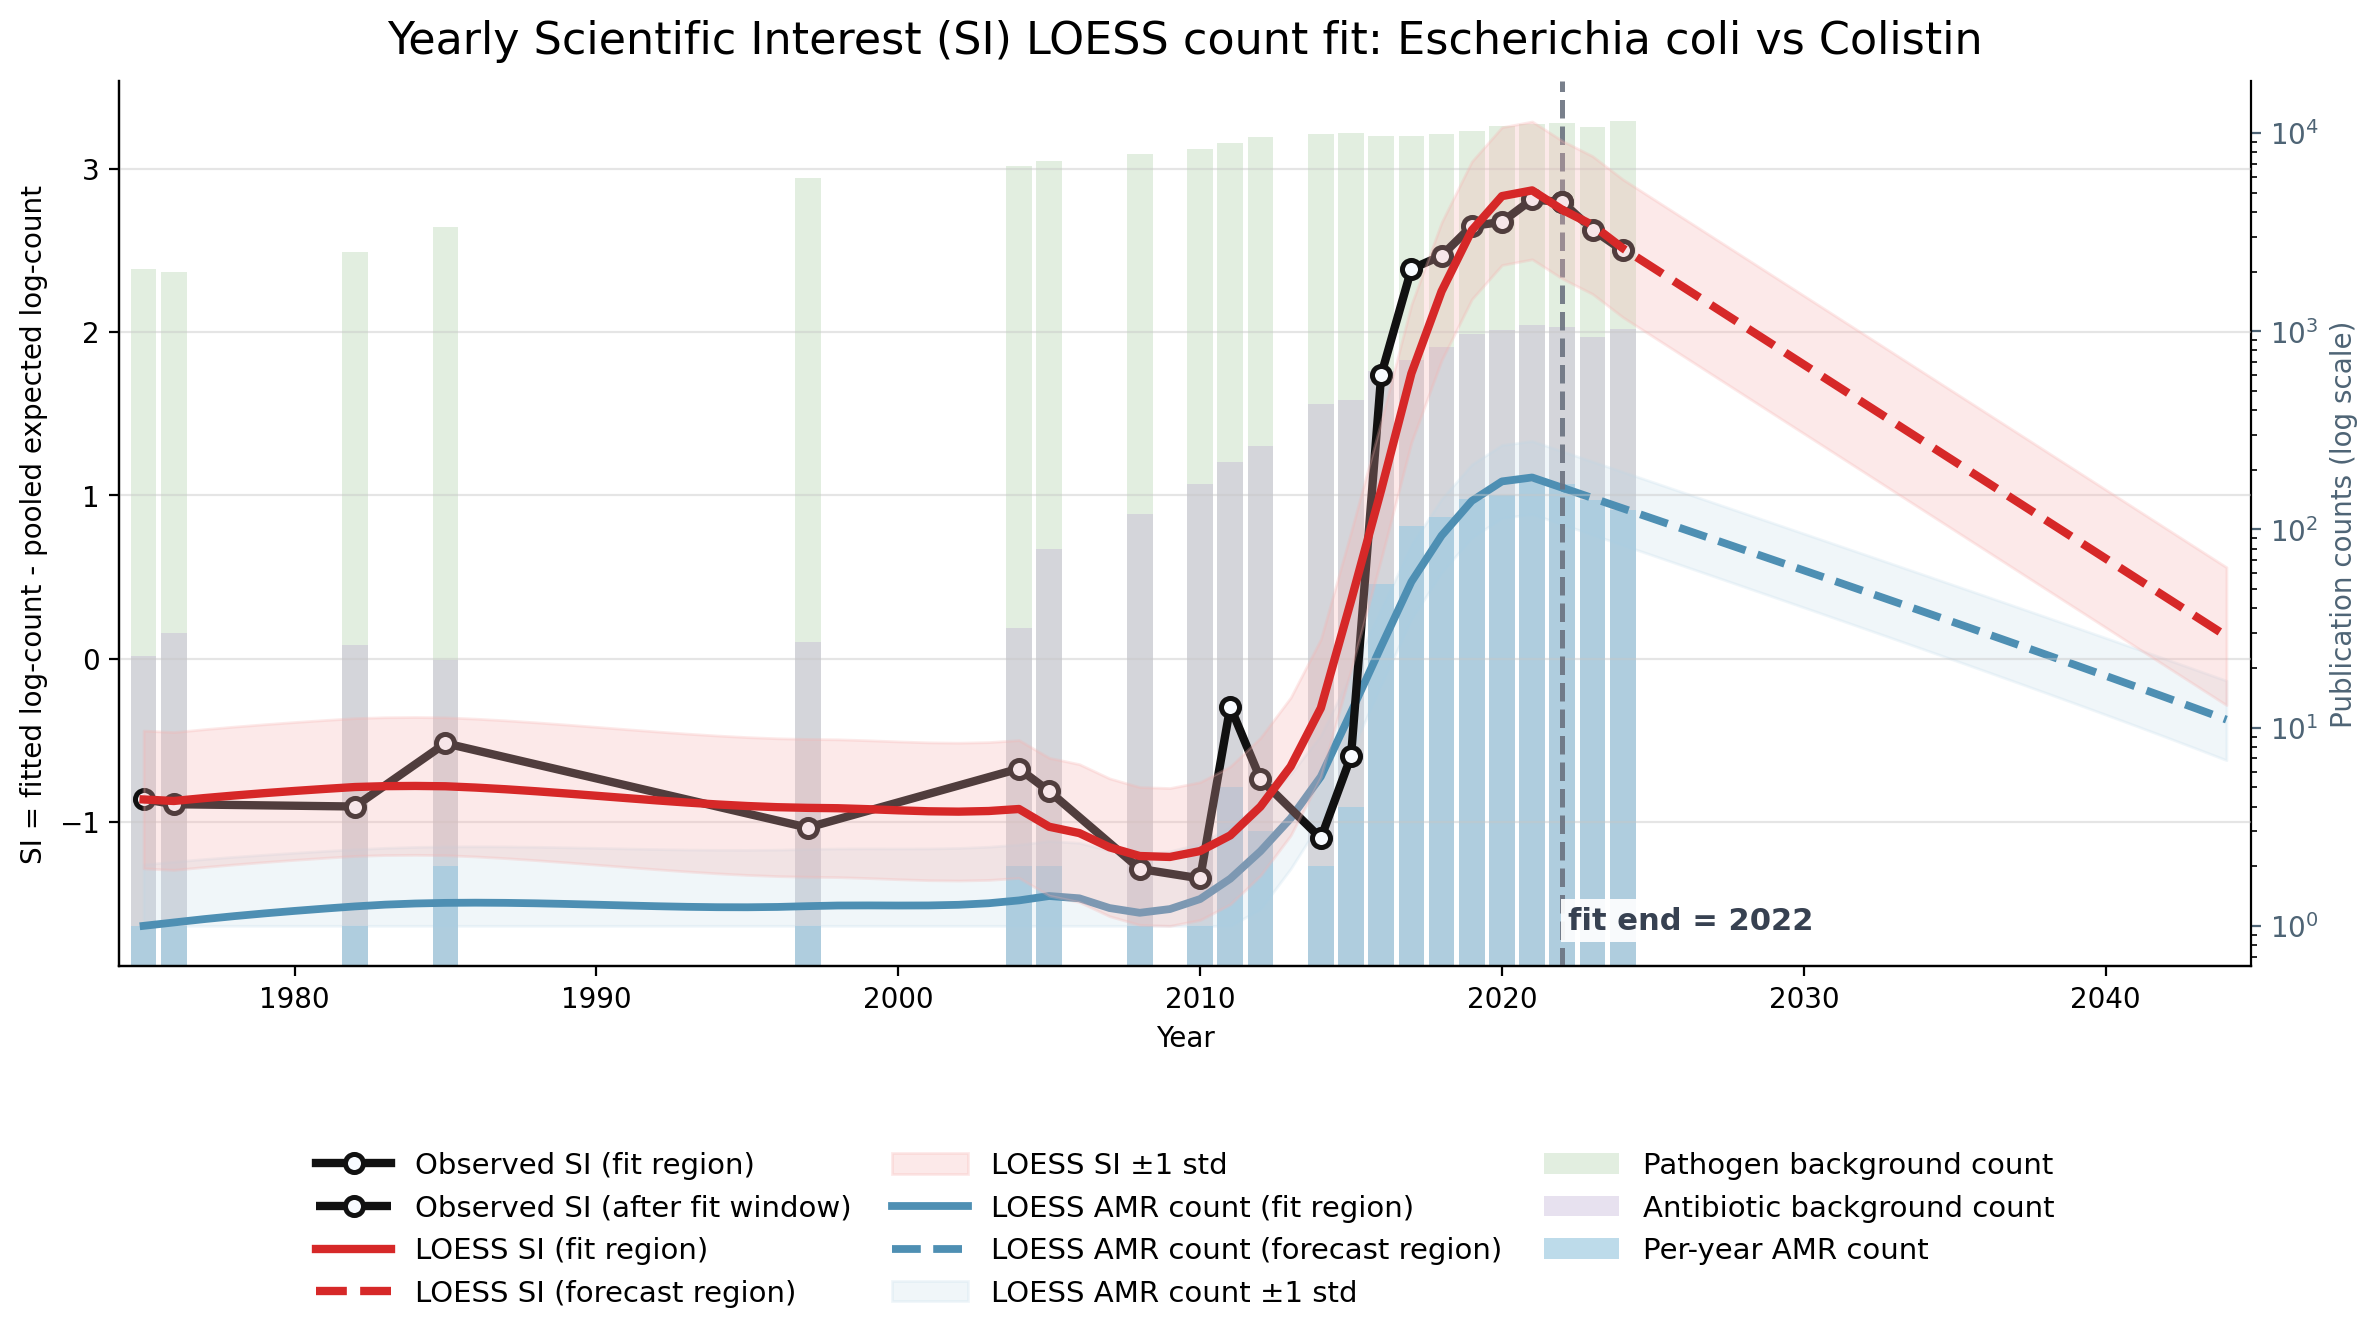

,year,observed_SI,observed_count,observed_log_count,expected_count_global,expected_log_count_global,expected_log_count_baseline,expected_count_baseline,predicted_log_count_loess,predicted_log_count_std,...,predicted_count_loess_upper_1std,predicted_SI,predicted_std,lower_1std,upper_1std,prediction_error,abs_error,within_1std,count_prediction_error_loess,count_abs_error_loess
0,1975,-0.859717,1,0.693147,3.724985,1.552864,1.552864,3.724985,0.690642,0.421745,...,2.041612,-0.862222,0.421745,-1.283968,-0.440477,0.002505,0.002505,True,0.005004,0.005004
1,1976,-0.891345,1,0.693147,3.876815,1.584492,1.584492,3.876815,0.712977,0.421745,...,2.110311,-0.871515,0.421745,-1.293260,-0.449769,-0.019830,0.019830,True,-0.040056,0.040056
2,1982,-0.905306,1,0.693147,3.945377,1.598453,1.598453,3.945377,0.812388,0.421745,...,2.435400,-0.786065,0.421745,-1.207811,-0.364320,-0.119241,0.119241,True,-0.253283,0.253283
3,1985,-0.518336,2,1.098612,4.037694,1.616949,1.616949,4.037694,0.835527,0.421745,...,2.515820,-0.781421,0.421745,-1.203167,-0.359676,0.263085,0.263085,True,0.693970,0.693970
4,1997,-1.034596,1,0.693147,4.627937,1.727743,1.727743,4.627937,0.814096,0.421745,...,2.441271,-0.913647,0.421745,-1.335393,-0.491902,-0.120948,0.120948,True,-0.257133,0.257133
5,2004,-0.673747,2,1.098612,4.884723,1.772360,1.772360,4.884723,0.851791,0.421745,...,2.573469,-0.920568,0.421745,-1.342314,-0.498823,0.246821,0.246821,True,0.656158,0.656158
6,2005,-0.812060,2,1.098612,5.757630,1.910672,1.910672,5.757630,0.881423,0.421745,...,2.680942,-1.029249,0.421745,-1.450994,-0.607504,0.217189,0.217189,True,0.585667,0.585667
7,2008,-1.287083,1,0.693147,6.244409,1.980230,1.980230,6.244409,0.771880,0.421745,...,2.299019,-1.208350,0.421745,-1.630096,-0.786605,-0.078732,0.078732,True,-0.163830,0.163830
8,2010,-1.345680,1,0.693147,6.681597,2.038827,2.038827,6.681597,0.860833,0.421745,...,2.605926,-1.177994,0.421745,-1.599740,-0.756249,-0.167686,0.167686,True,-0.365131,0.365131
9,2011,-0.294265,5,1.791759,7.052836,2.086024,2.086024,7.052836,1.003754,0.421745,...,3.159934,-1.082270,0.421745,-1.504016,-0.660525,0.788006,0.788006,False,3.271495,3.271495


LOESS fraction: 0.6
LOESS degree: 2
Training residual std on log-count scale: 0.42174543611203985
Latest observed year: 2024


In [10]:
result = plot_yearly_si_pair(
    si_df=si_df,
    pathogen="Escherichia coli",
    antibiotic="Colistin",
    fit_start_year=1970,
    fit_end_year=2022,
    num_additional_years=20,
    loess_frac=0.6,
    loess_degree=2,
    tail_damping_years=None,
)

display(result["comparison_df"])
print("LOESS fraction:", result["loess_fit"]["frac"])
print("LOESS degree:", result["loess_fit"]["degree"])
print("Training residual std on log-count scale:", result["loess_fit"]["residual_std"])
print("Latest observed year:", result["latest_available_year"])


## Pareto-front examples

This is the yearly equivalent of the interval Pareto workflow: first identify pairs that are non-dominated in mean `SI` and mean AMR count, then generate yearly prediction plots for those pairs.


,pareto_shell,pathogen,antibiotic,mean_SI,mean_count,total_count,n_intervals,n_years,latest_year
0,1,Enterococcus faecium,Vancomycin,2.252888,60.351351,2233,37,37,2024
1,1,Escherichia coli,Ampicillin,1.690067,65.320000,3266,50,50,2024
2,2,Helicobacter pylori,Clarithromycin,1.962170,54.250000,1736,32,32,2024
3,2,Escherichia coli,Ciprofloxacin,1.344040,59.918919,2217,37,37,2024
4,3,Helicobacter pylori,Metronidazole,1.680385,37.000000,1332,36,36,2024
5,3,Mycobacterium tuberculosis,Rifampicin,1.527835,45.872340,2156,47,47,2025
6,3,Staphylococcus aureus,Vancomycin,1.238002,48.976744,2106,43,43,2024
7,3,Escherichia coli,Colistin,0.526592,54.545455,1200,22,22,2024
8,4,Enterococcus faecalis,Vancomycin,1.594353,26.972973,998,37,37,2024
9,4,Staphylococcus aureus,Oxacillin,1.390655,33.346939,1634,49,49,2024


Plotting Enterococcus faecium vs Vancomycin


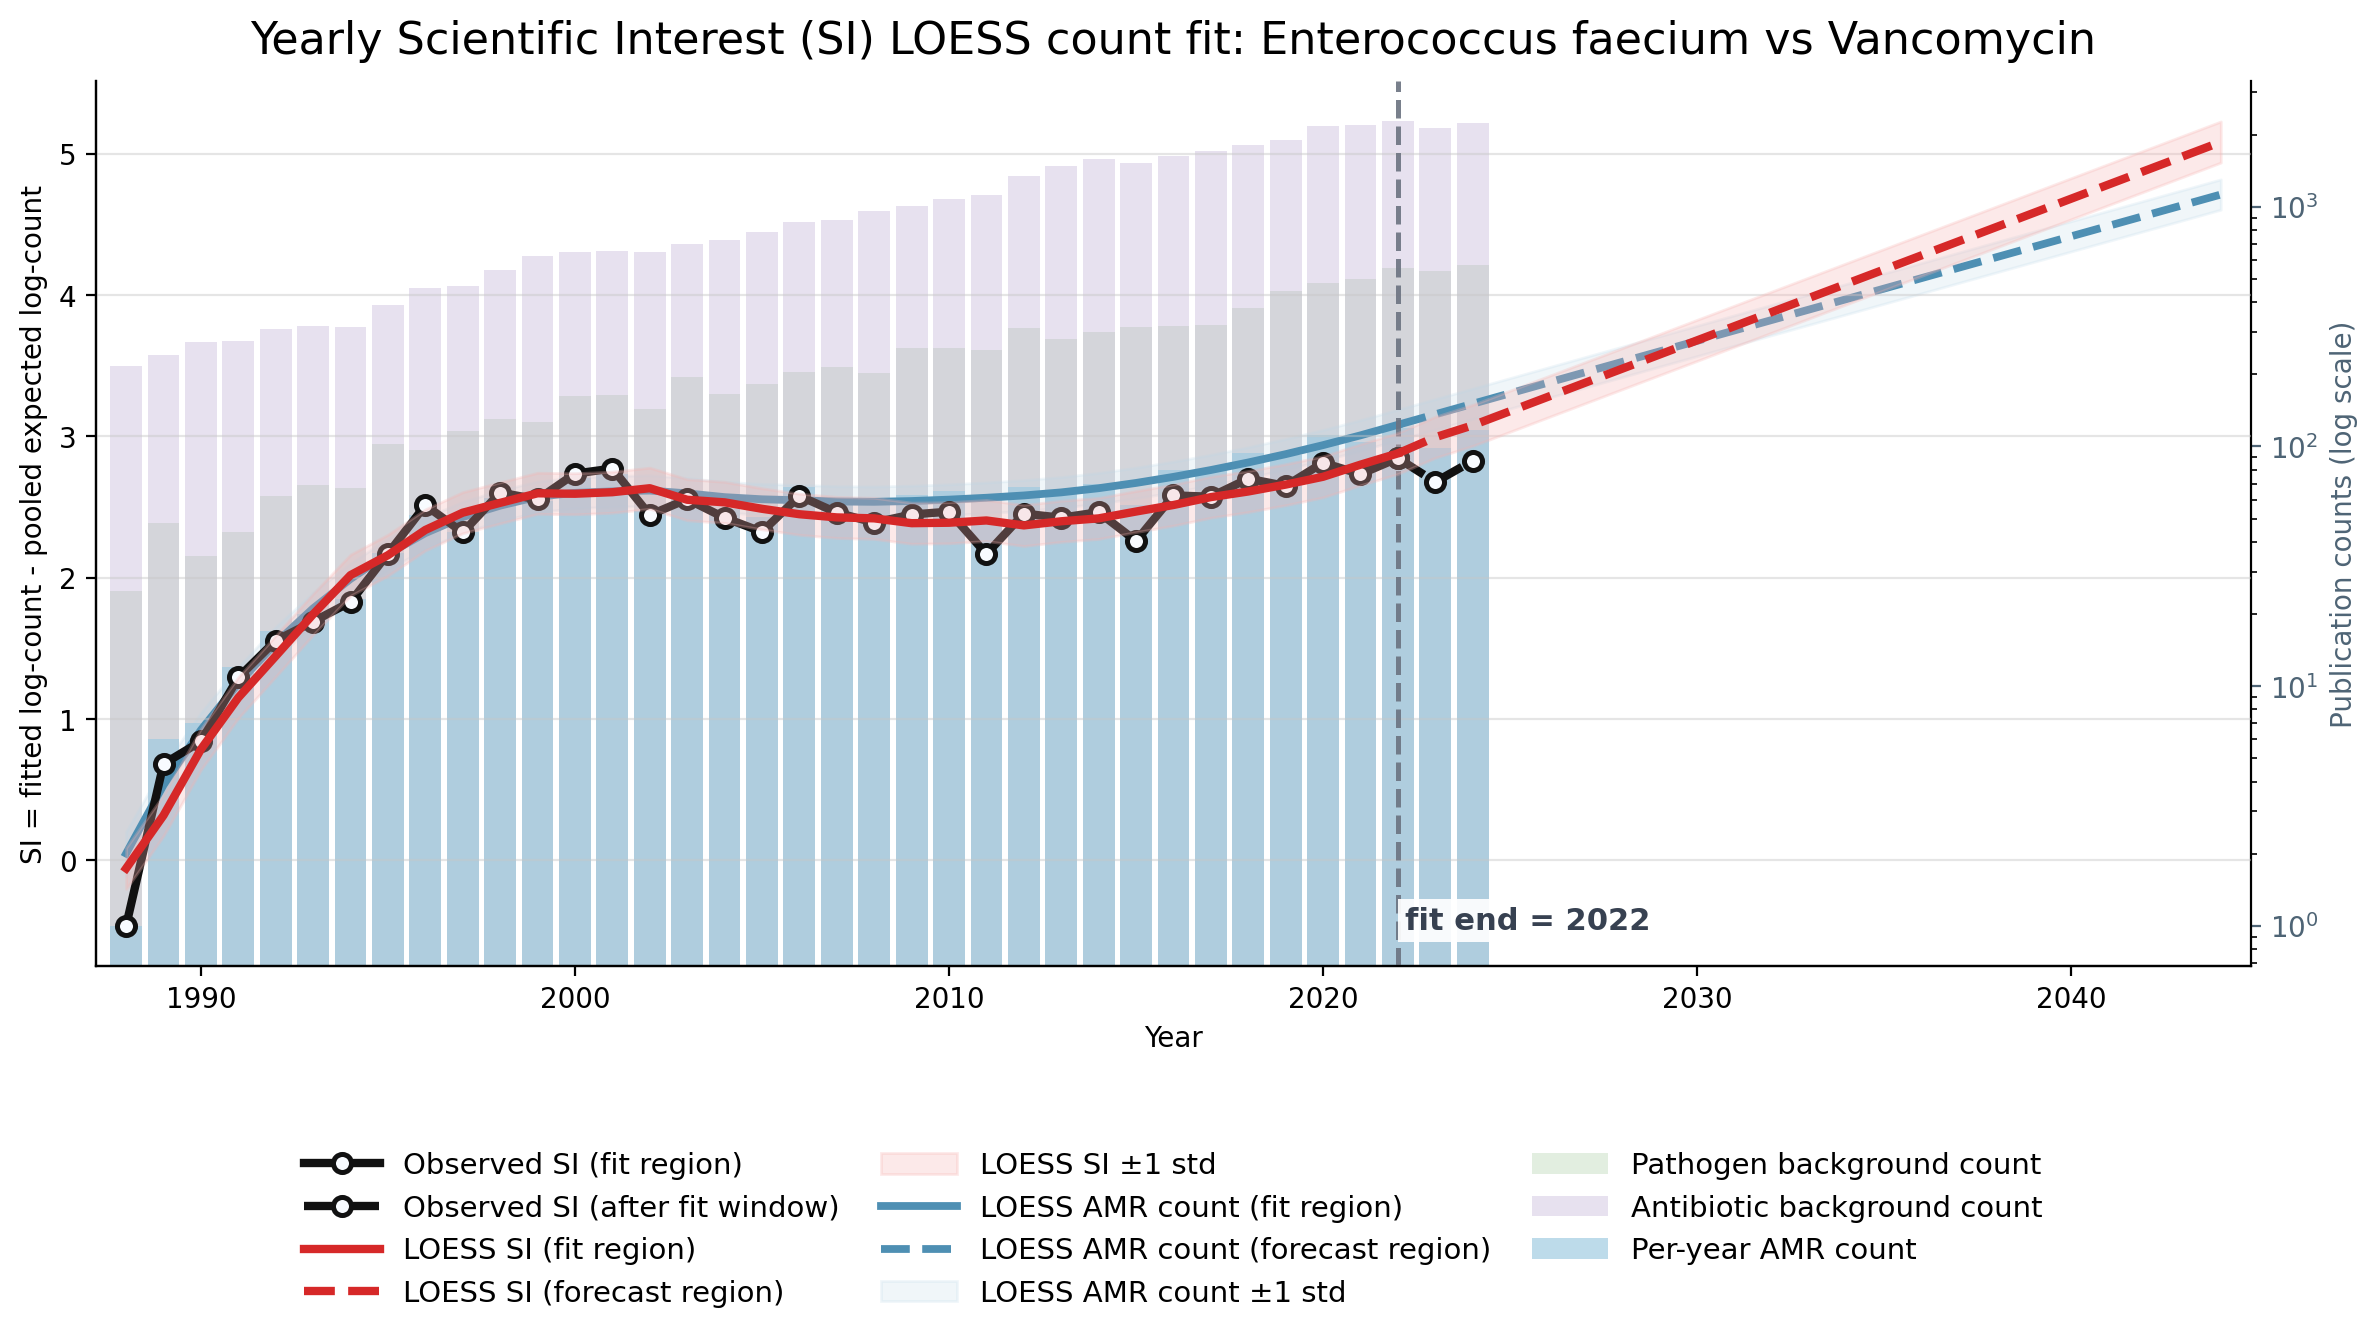

Plotting Escherichia coli vs Ampicillin


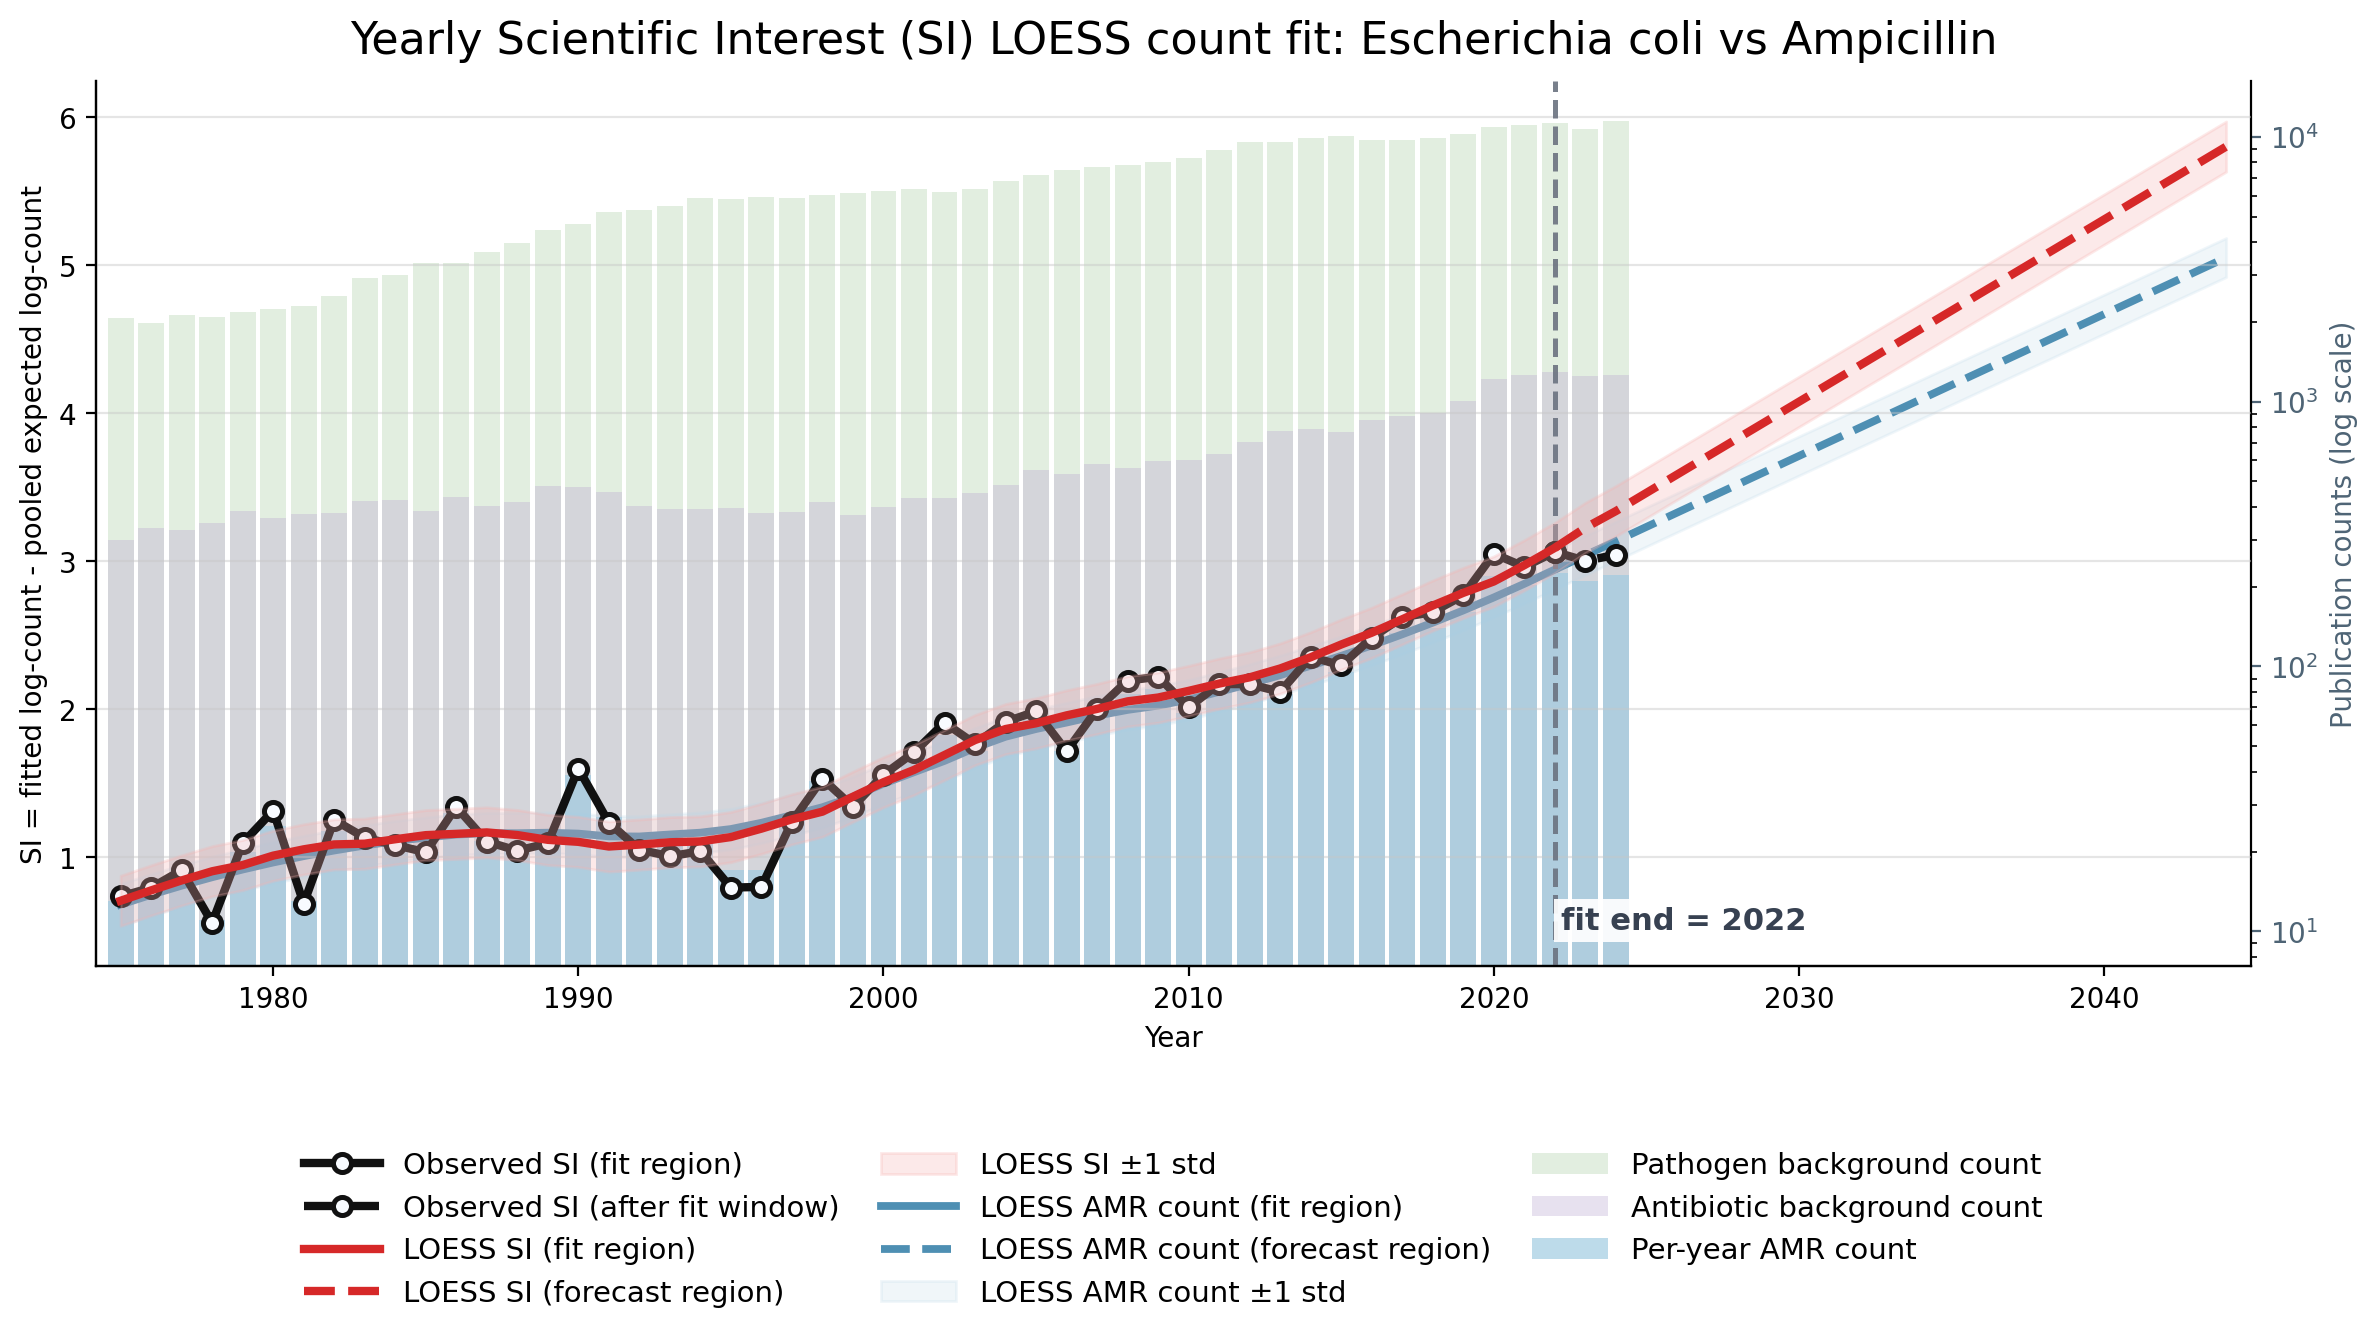

Plotting Helicobacter pylori vs Clarithromycin


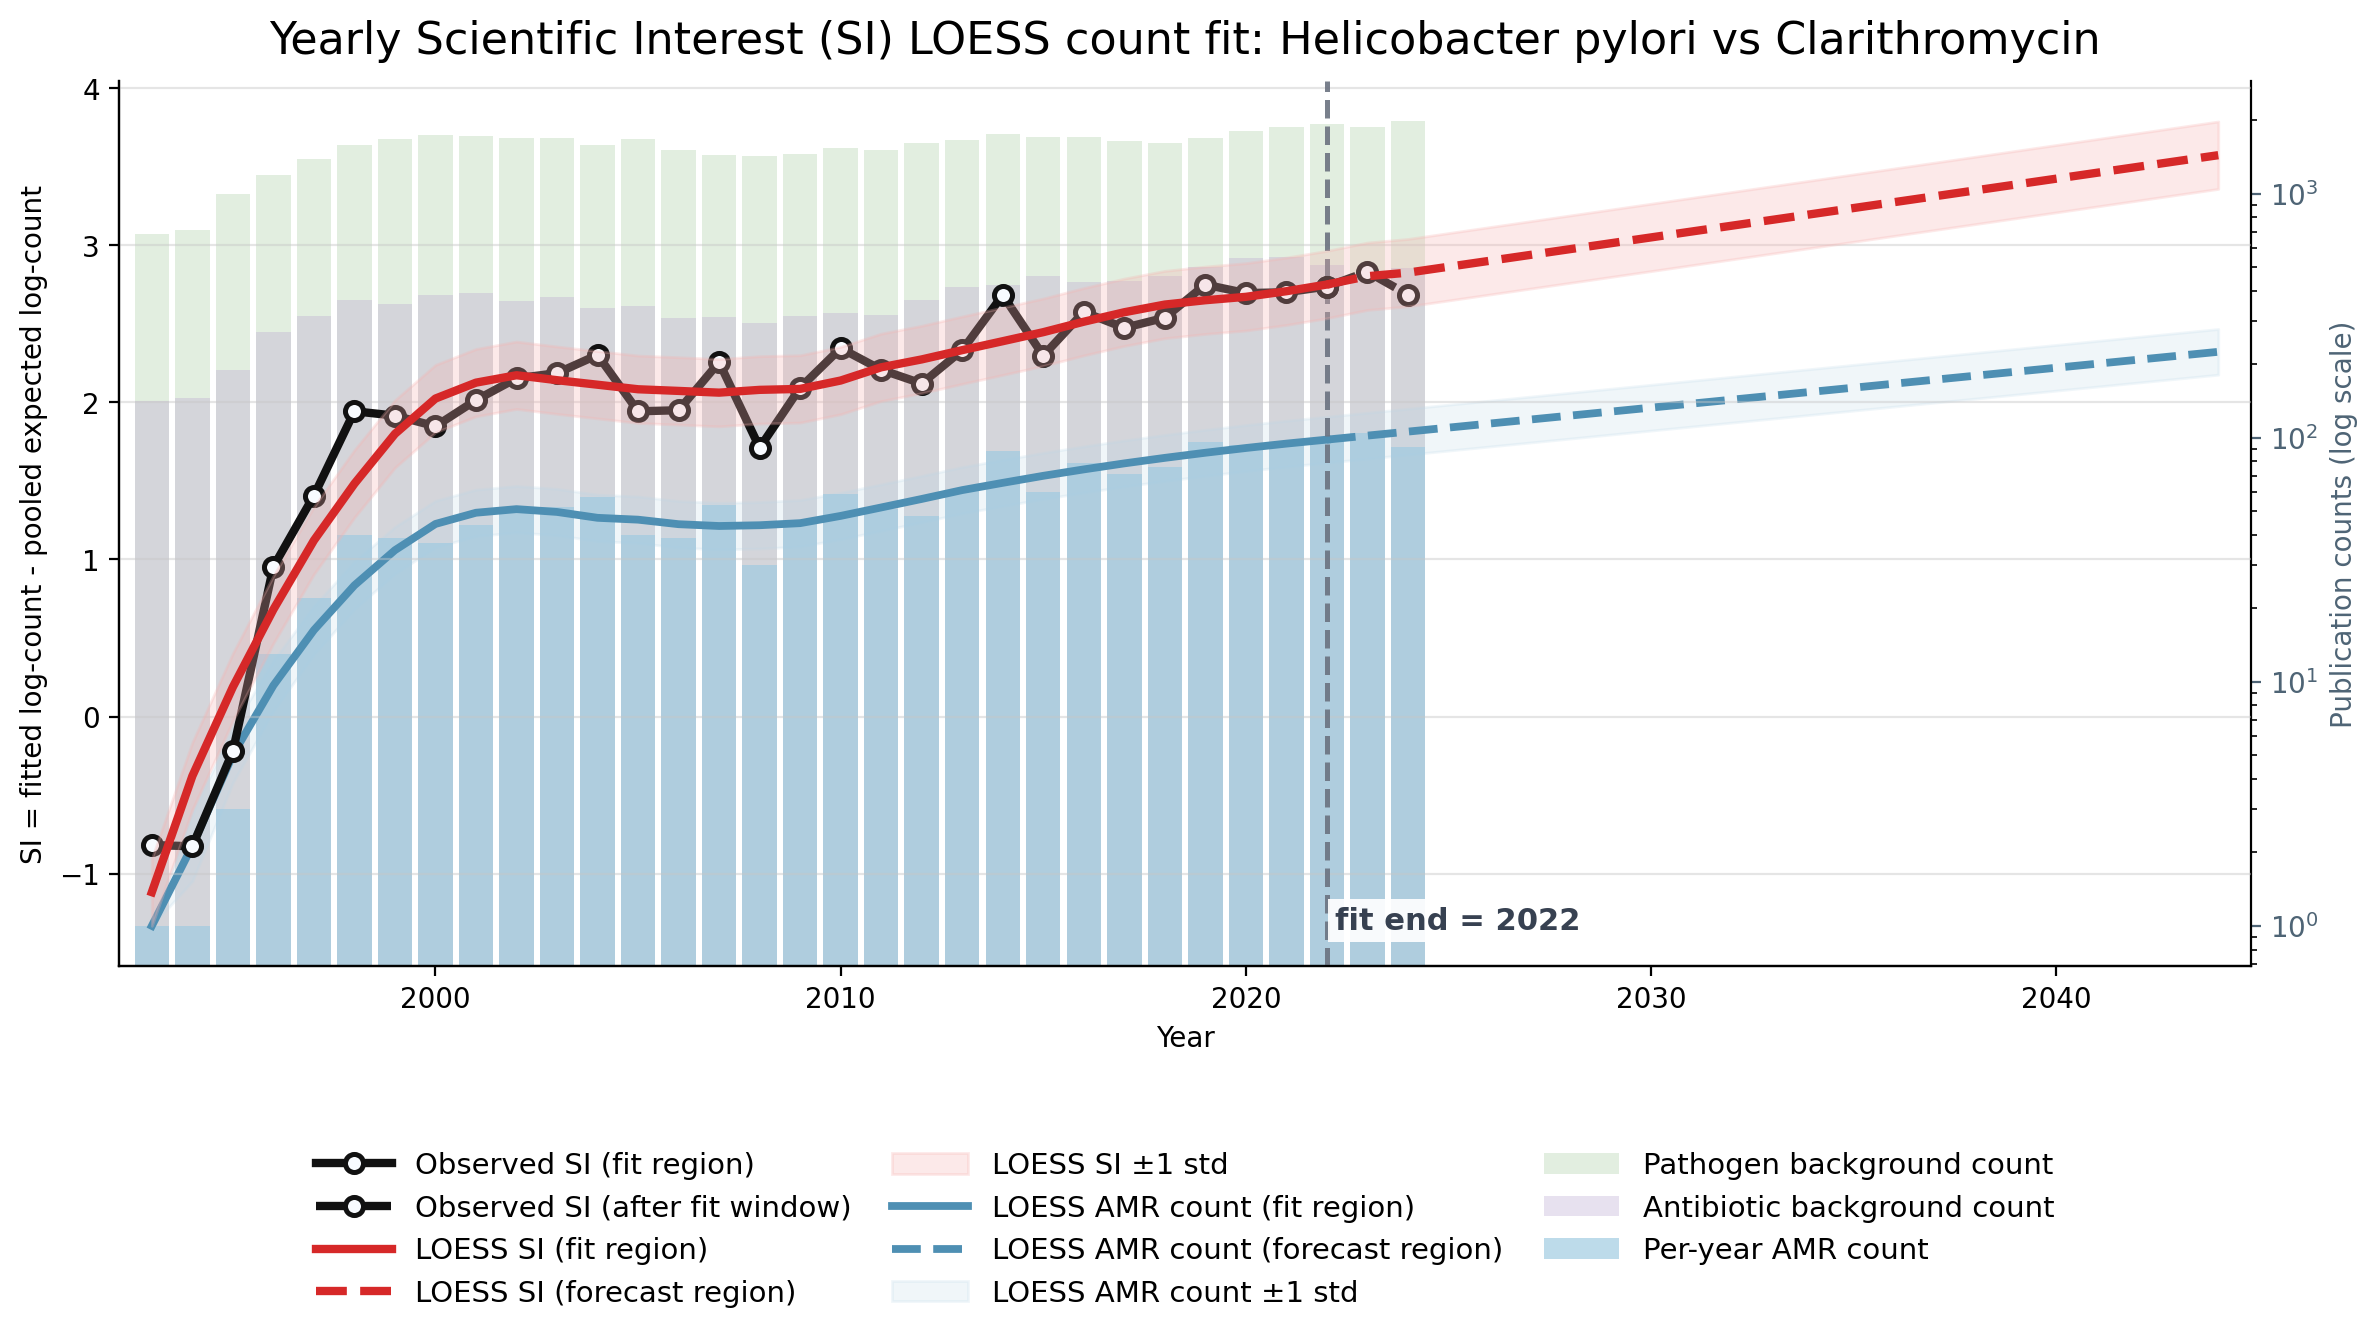

Plotting Escherichia coli vs Ciprofloxacin


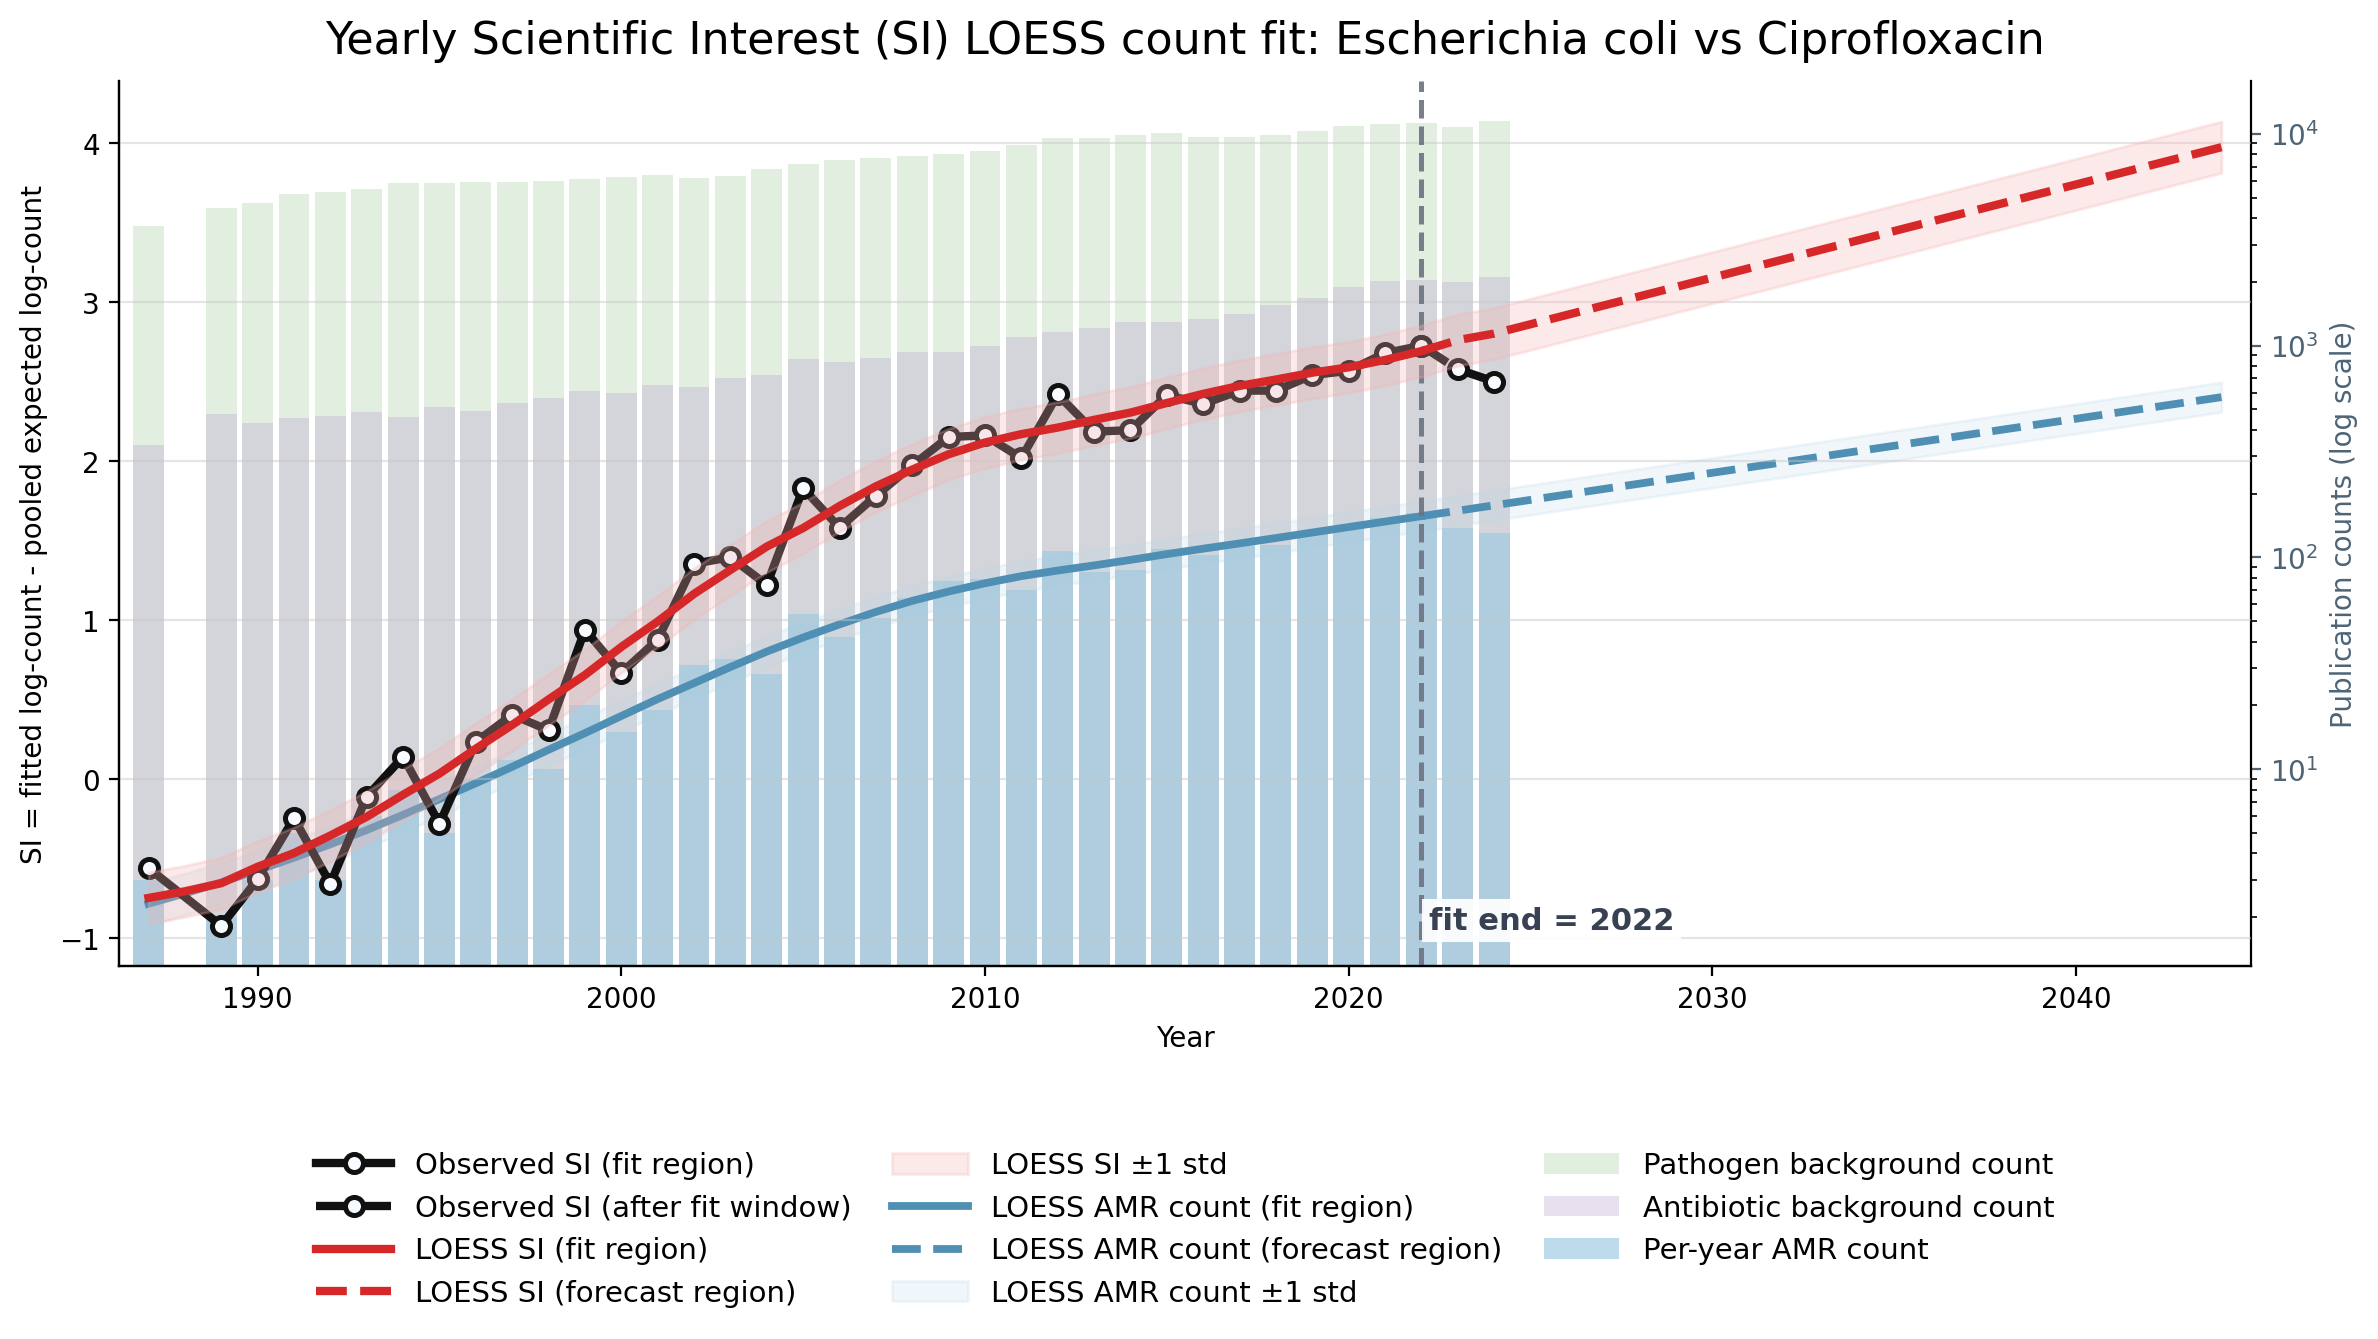

Plotting Helicobacter pylori vs Metronidazole


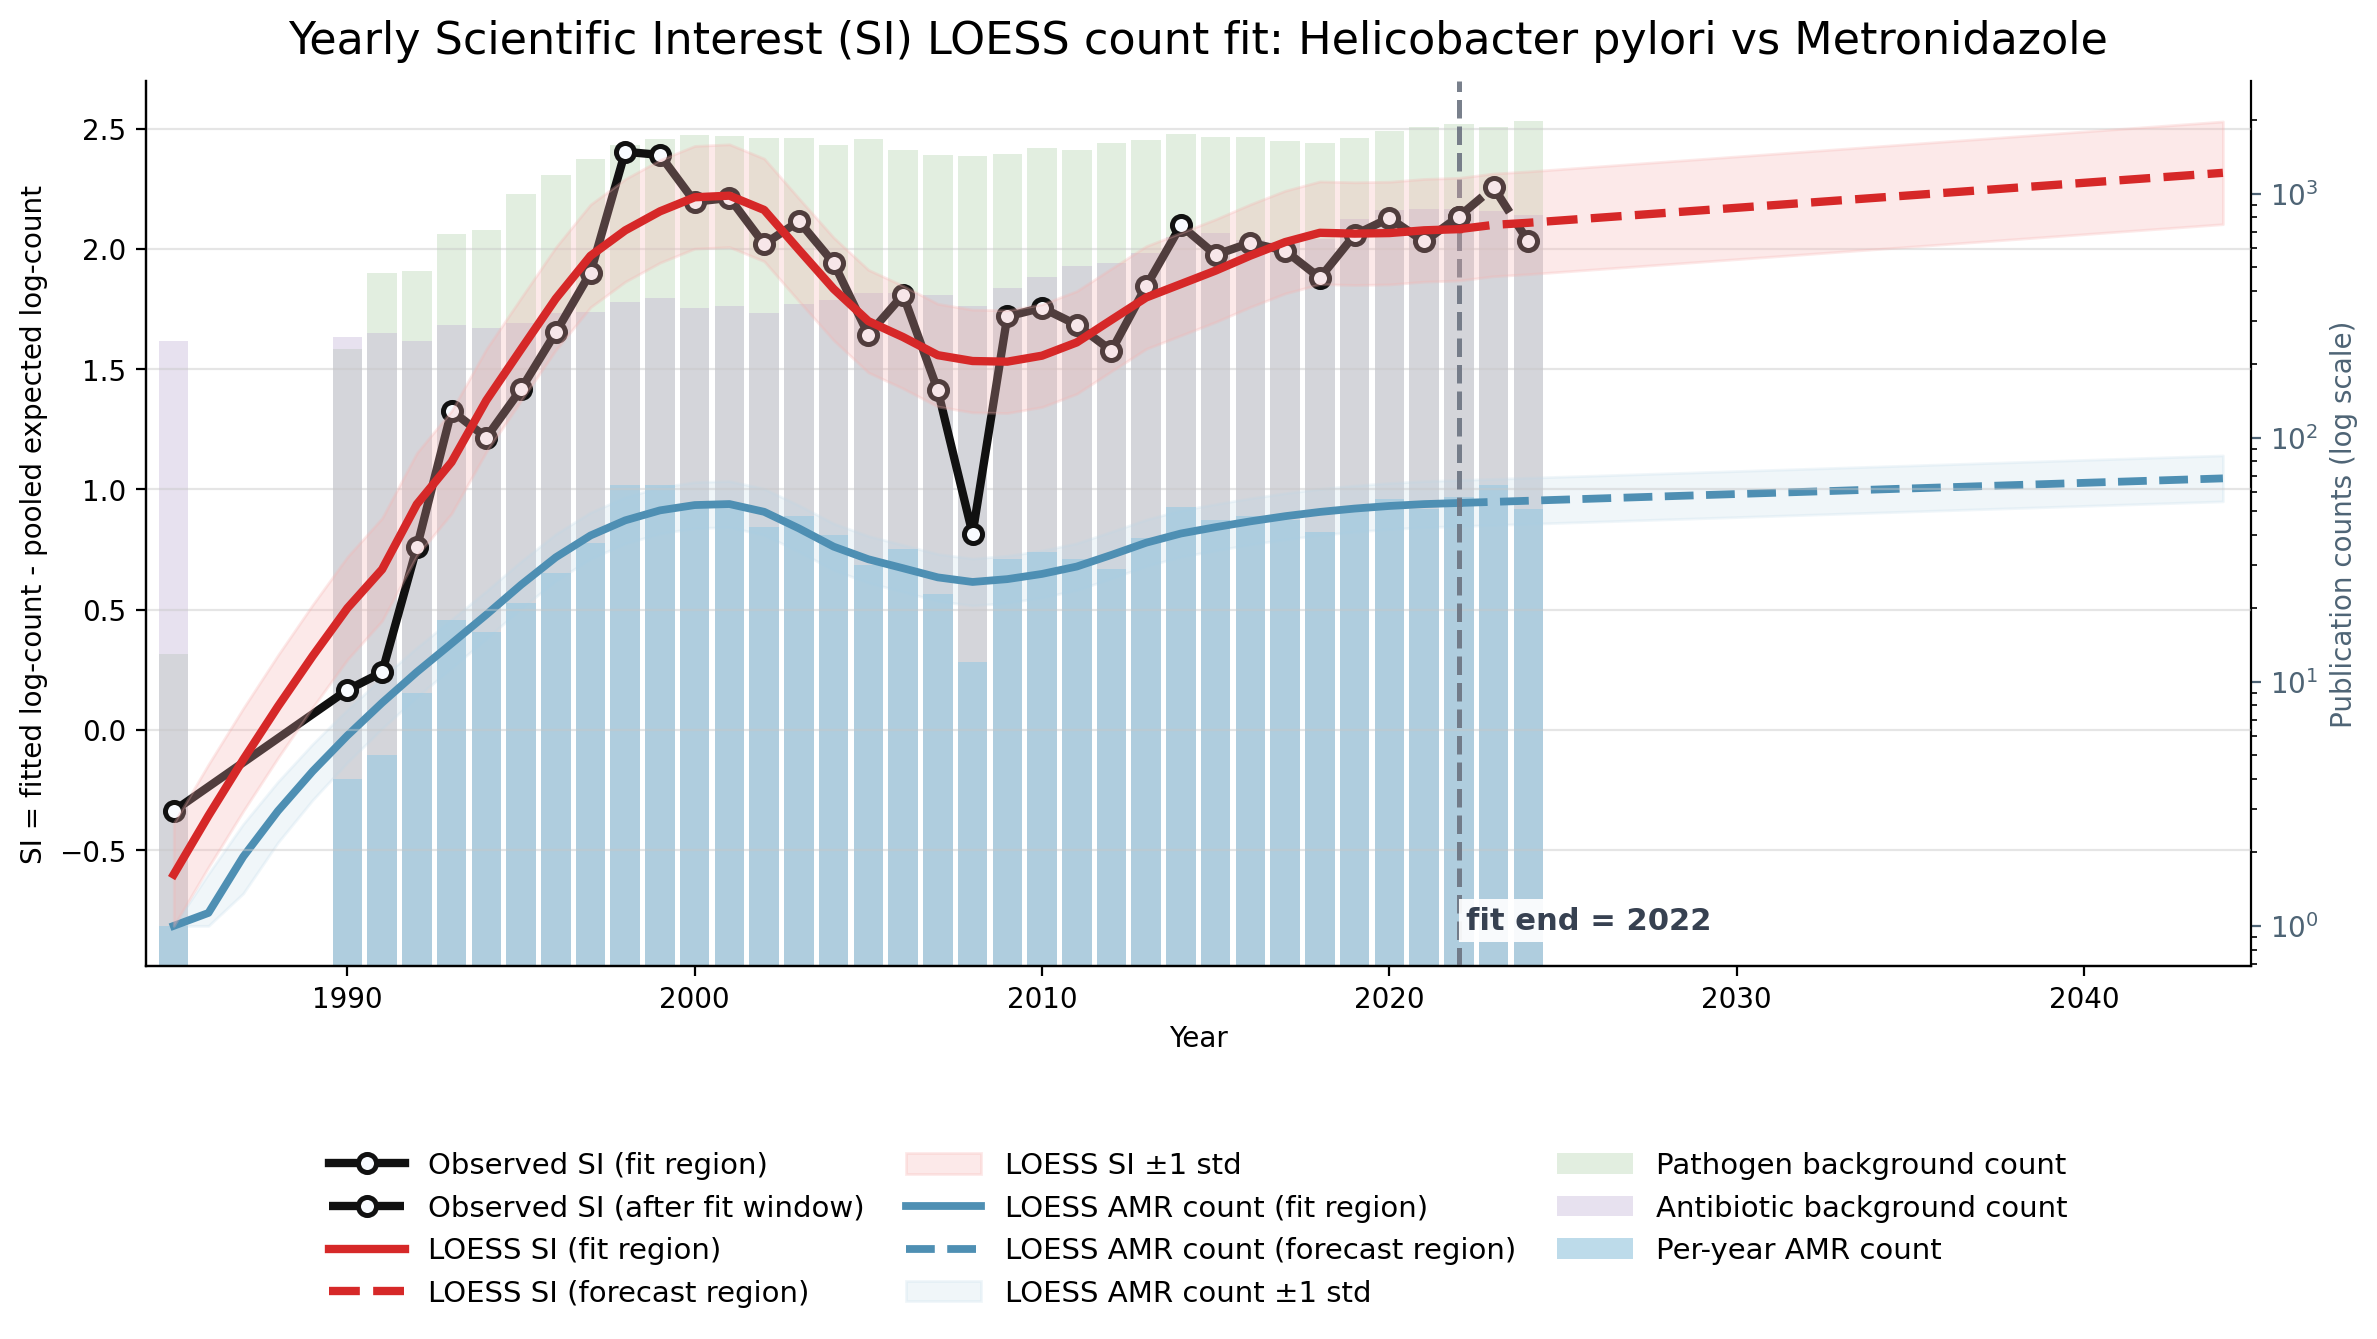

Plotting Mycobacterium tuberculosis vs Rifampicin


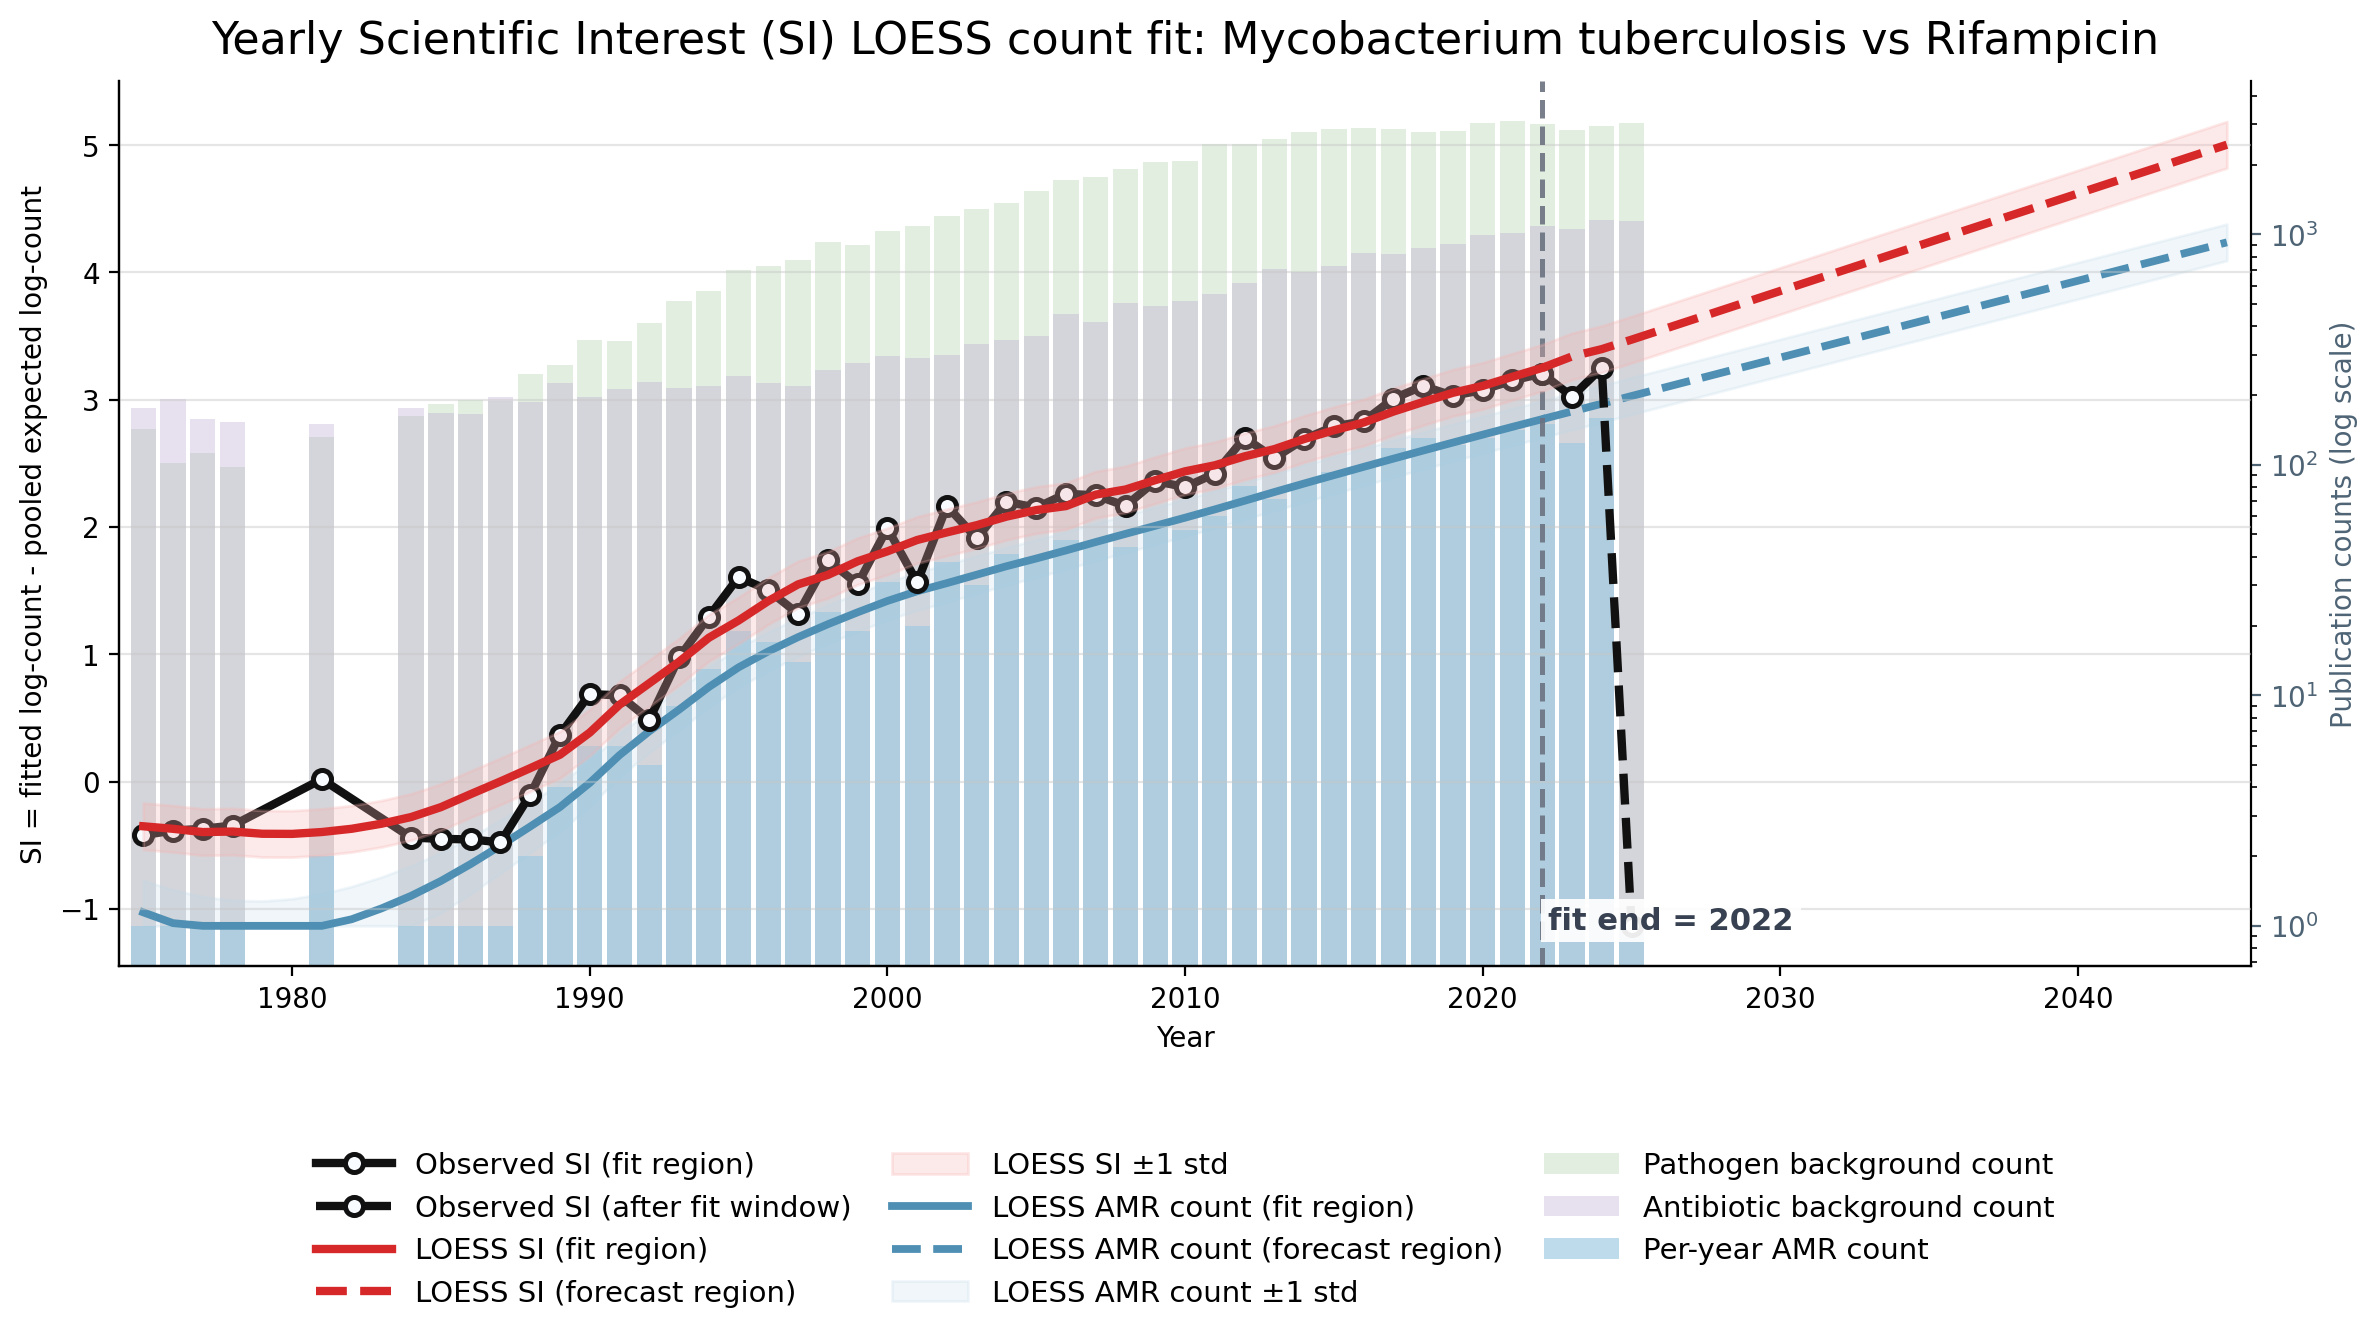

Plotting Staphylococcus aureus vs Vancomycin


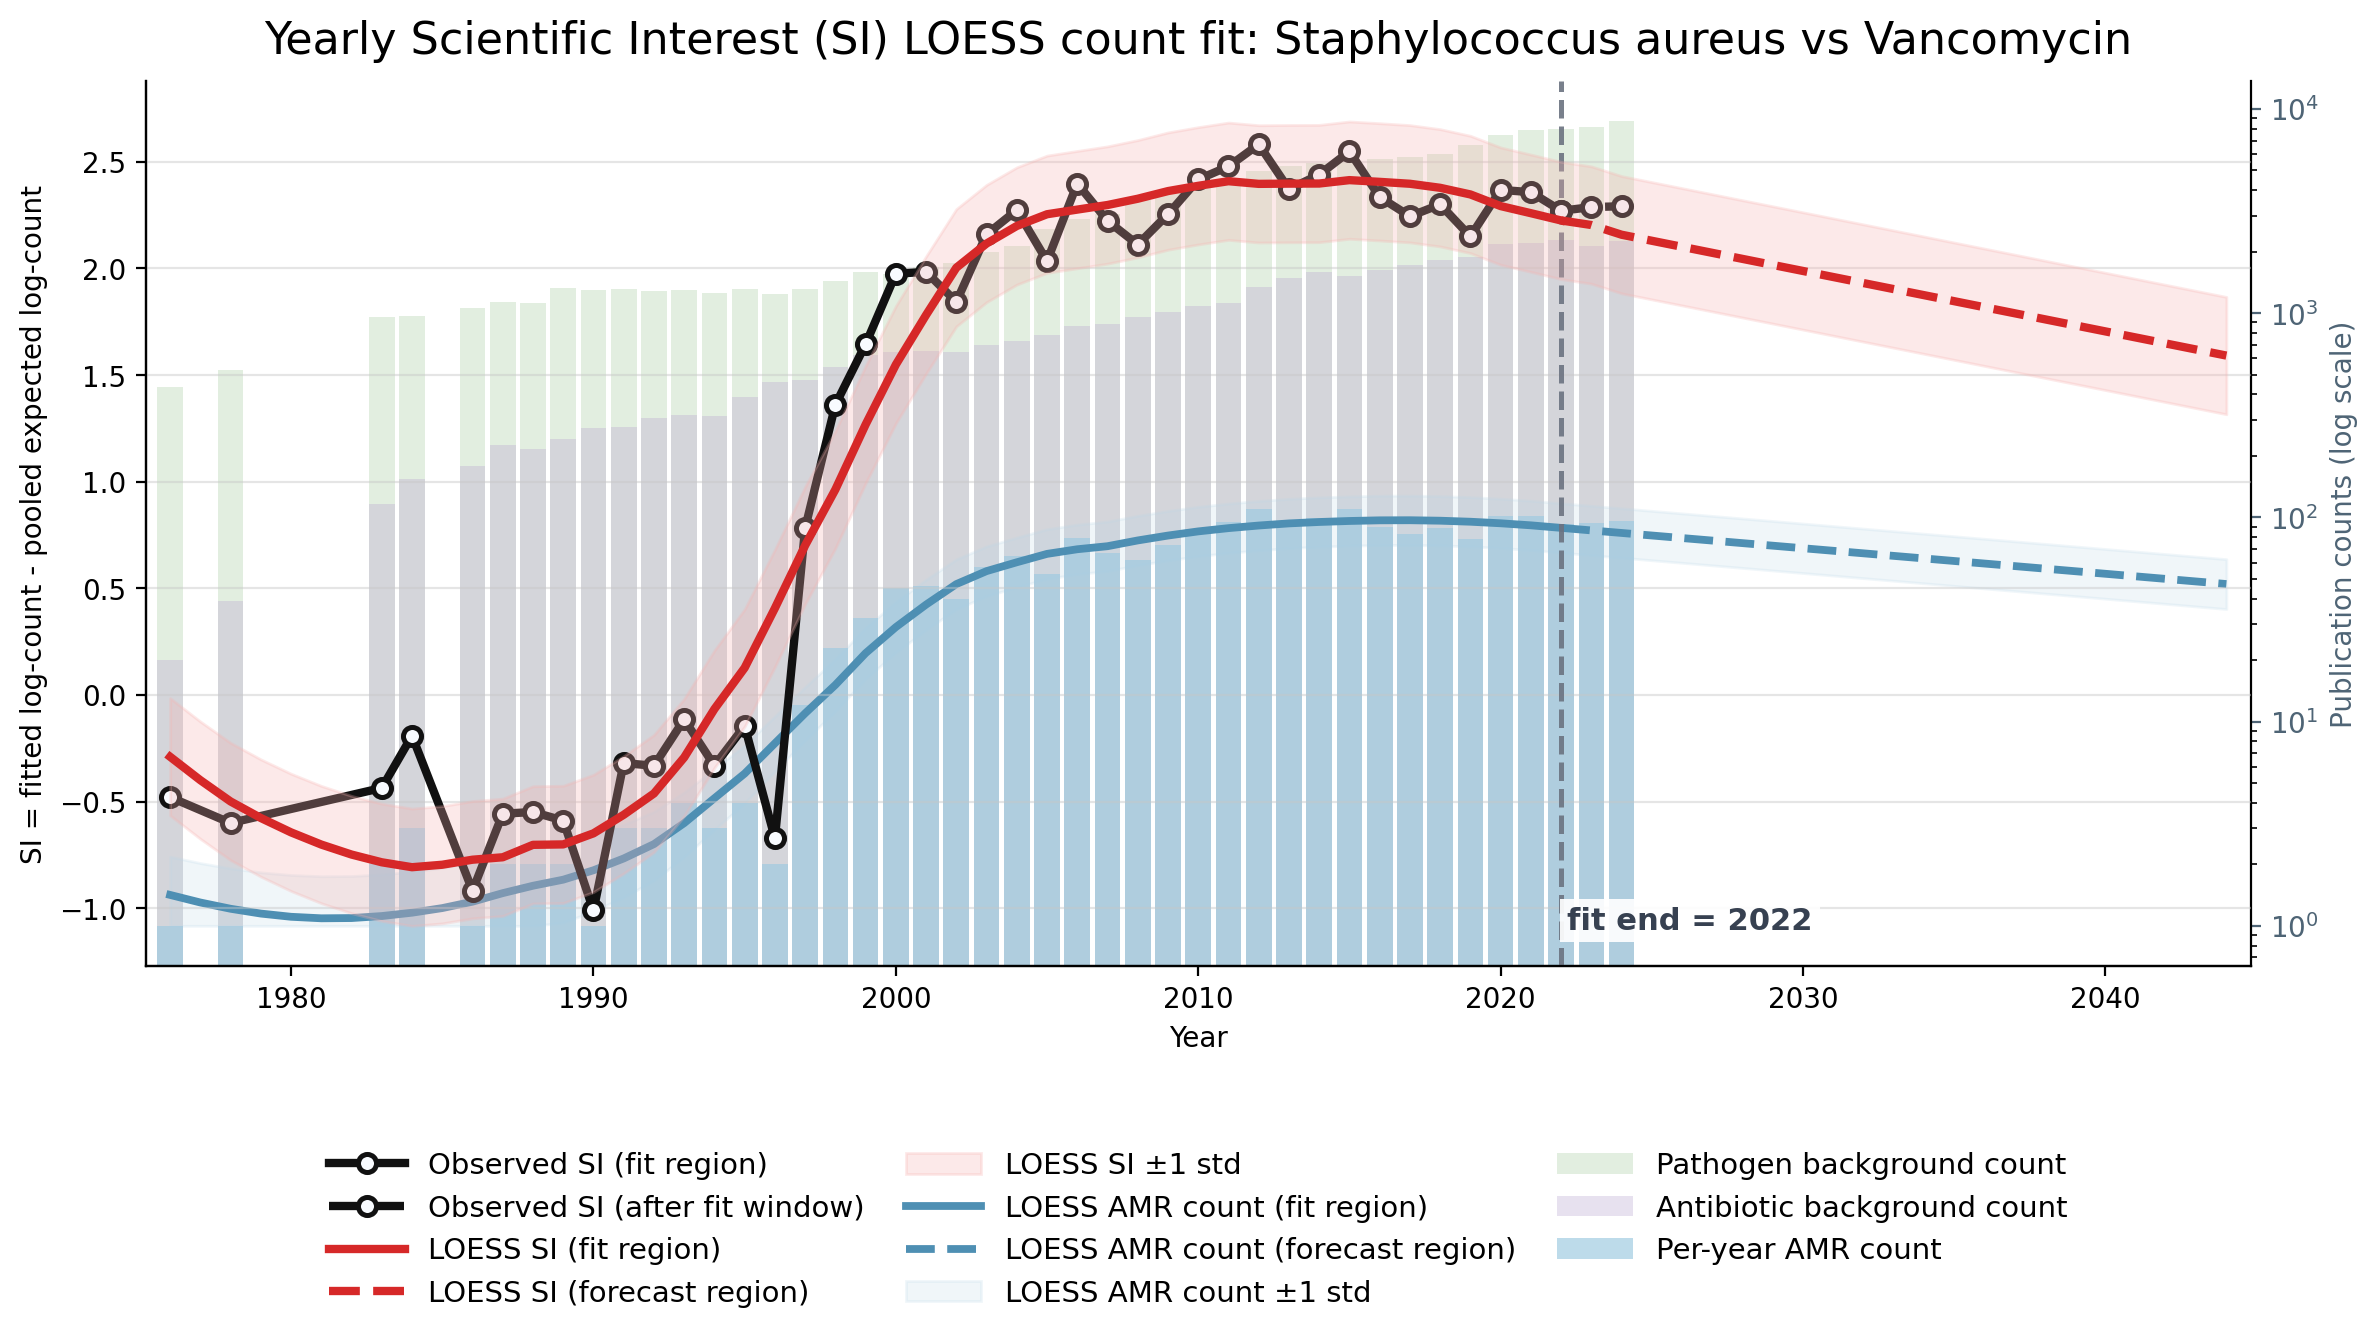

Plotting Escherichia coli vs Colistin


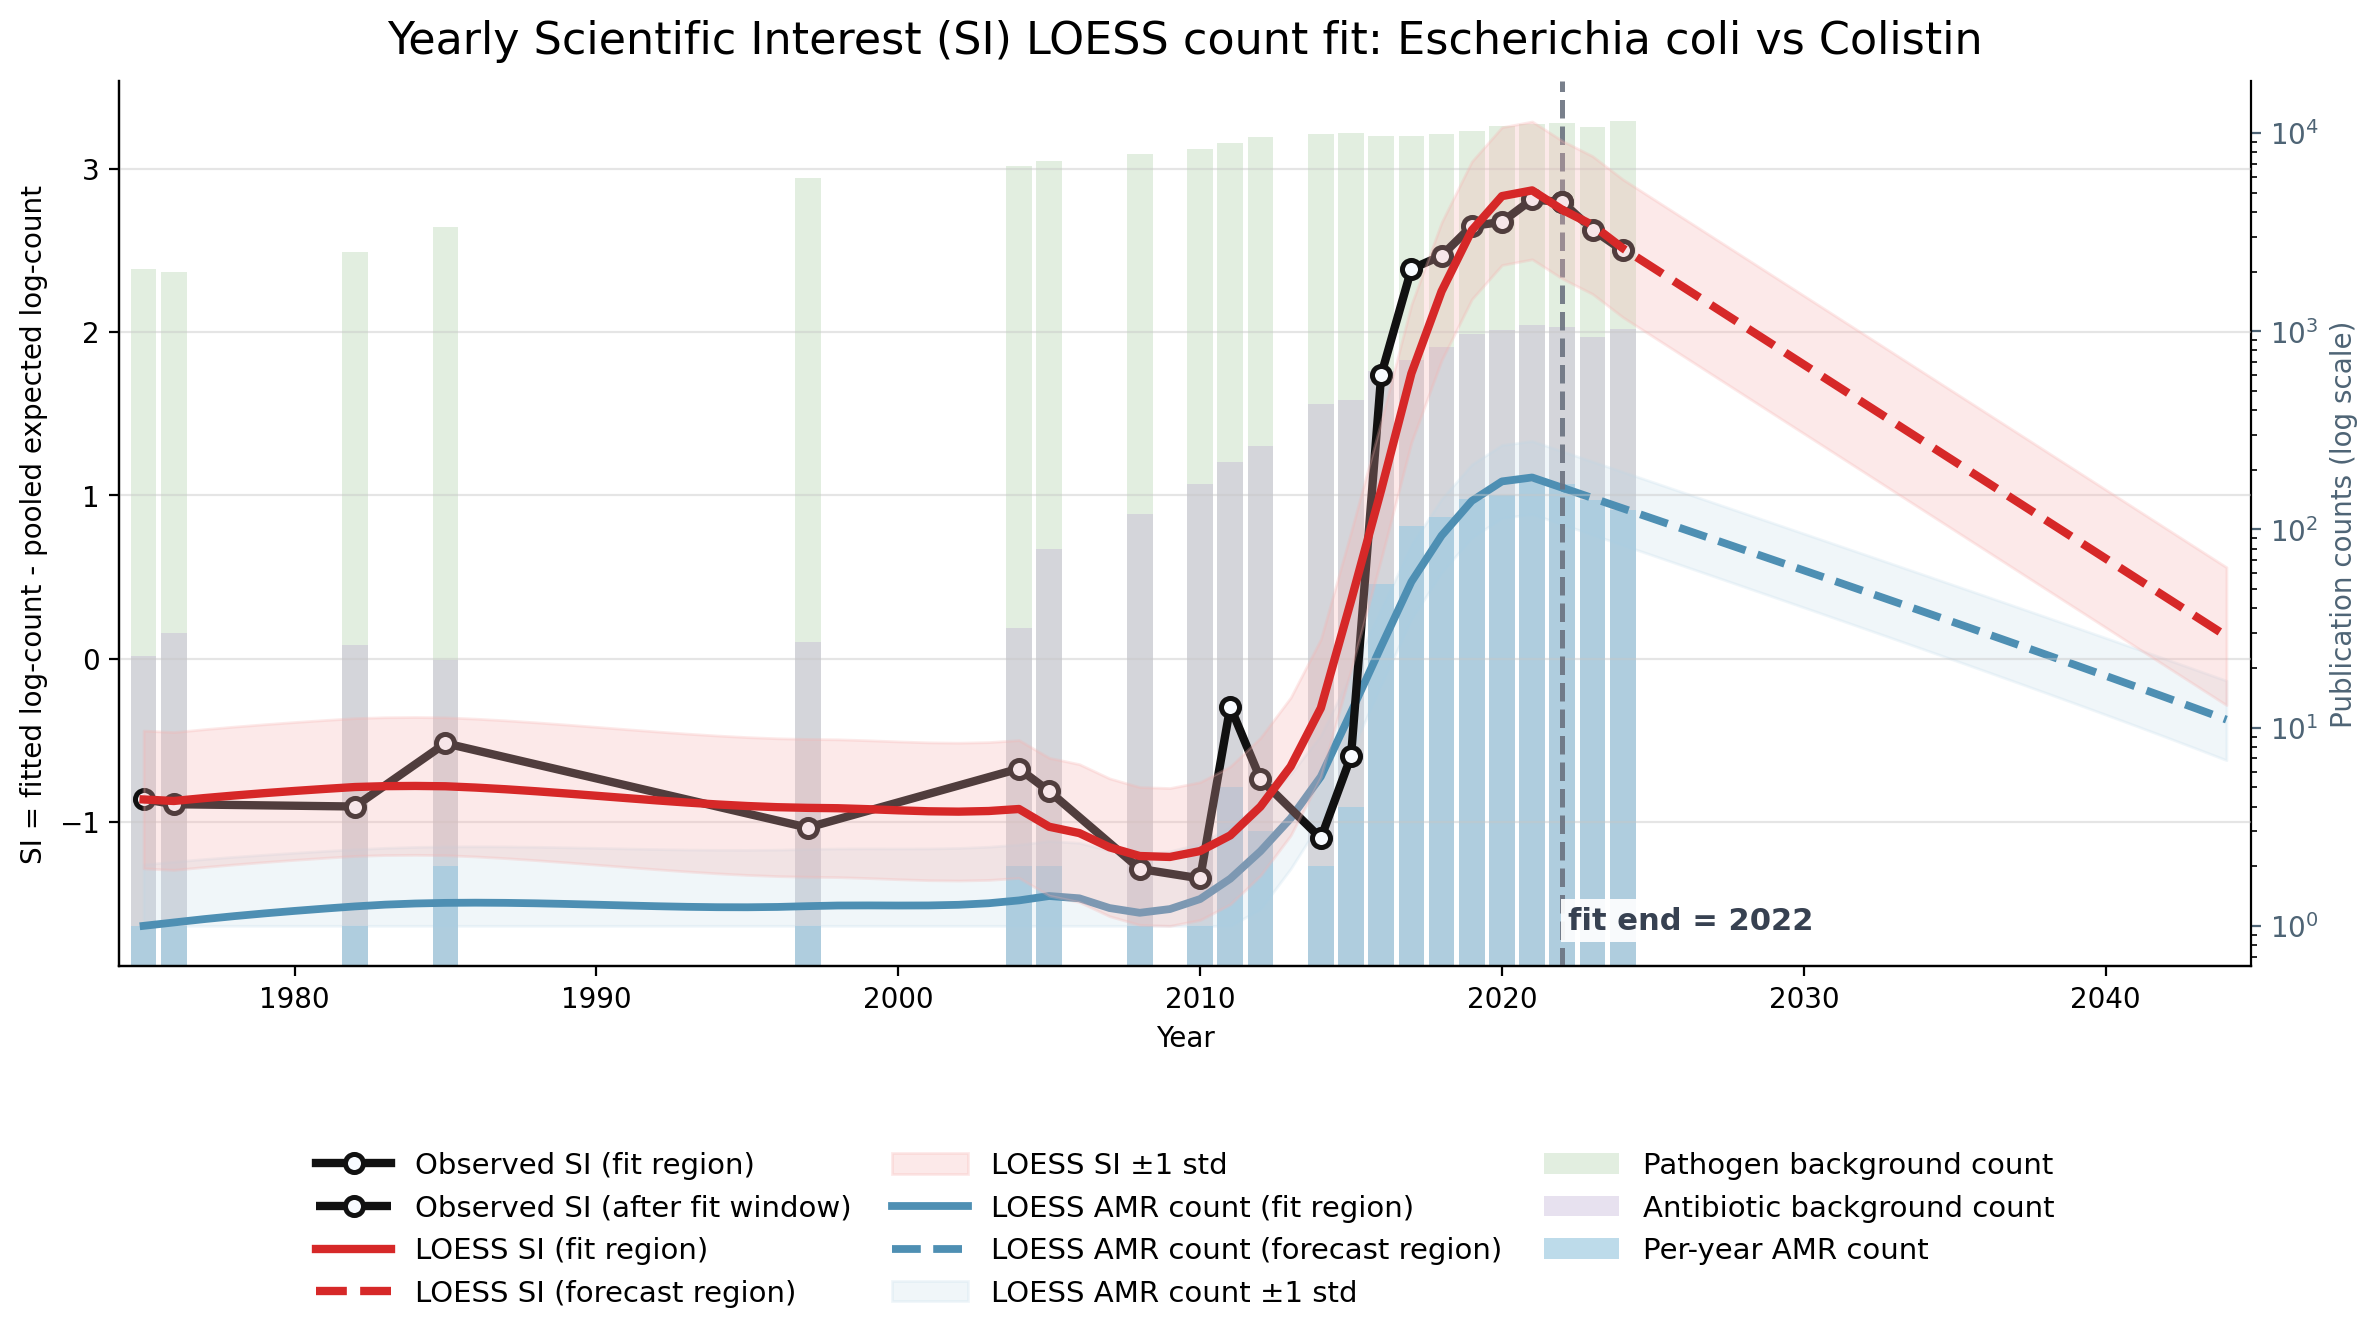

Plotting Enterococcus faecalis vs Vancomycin


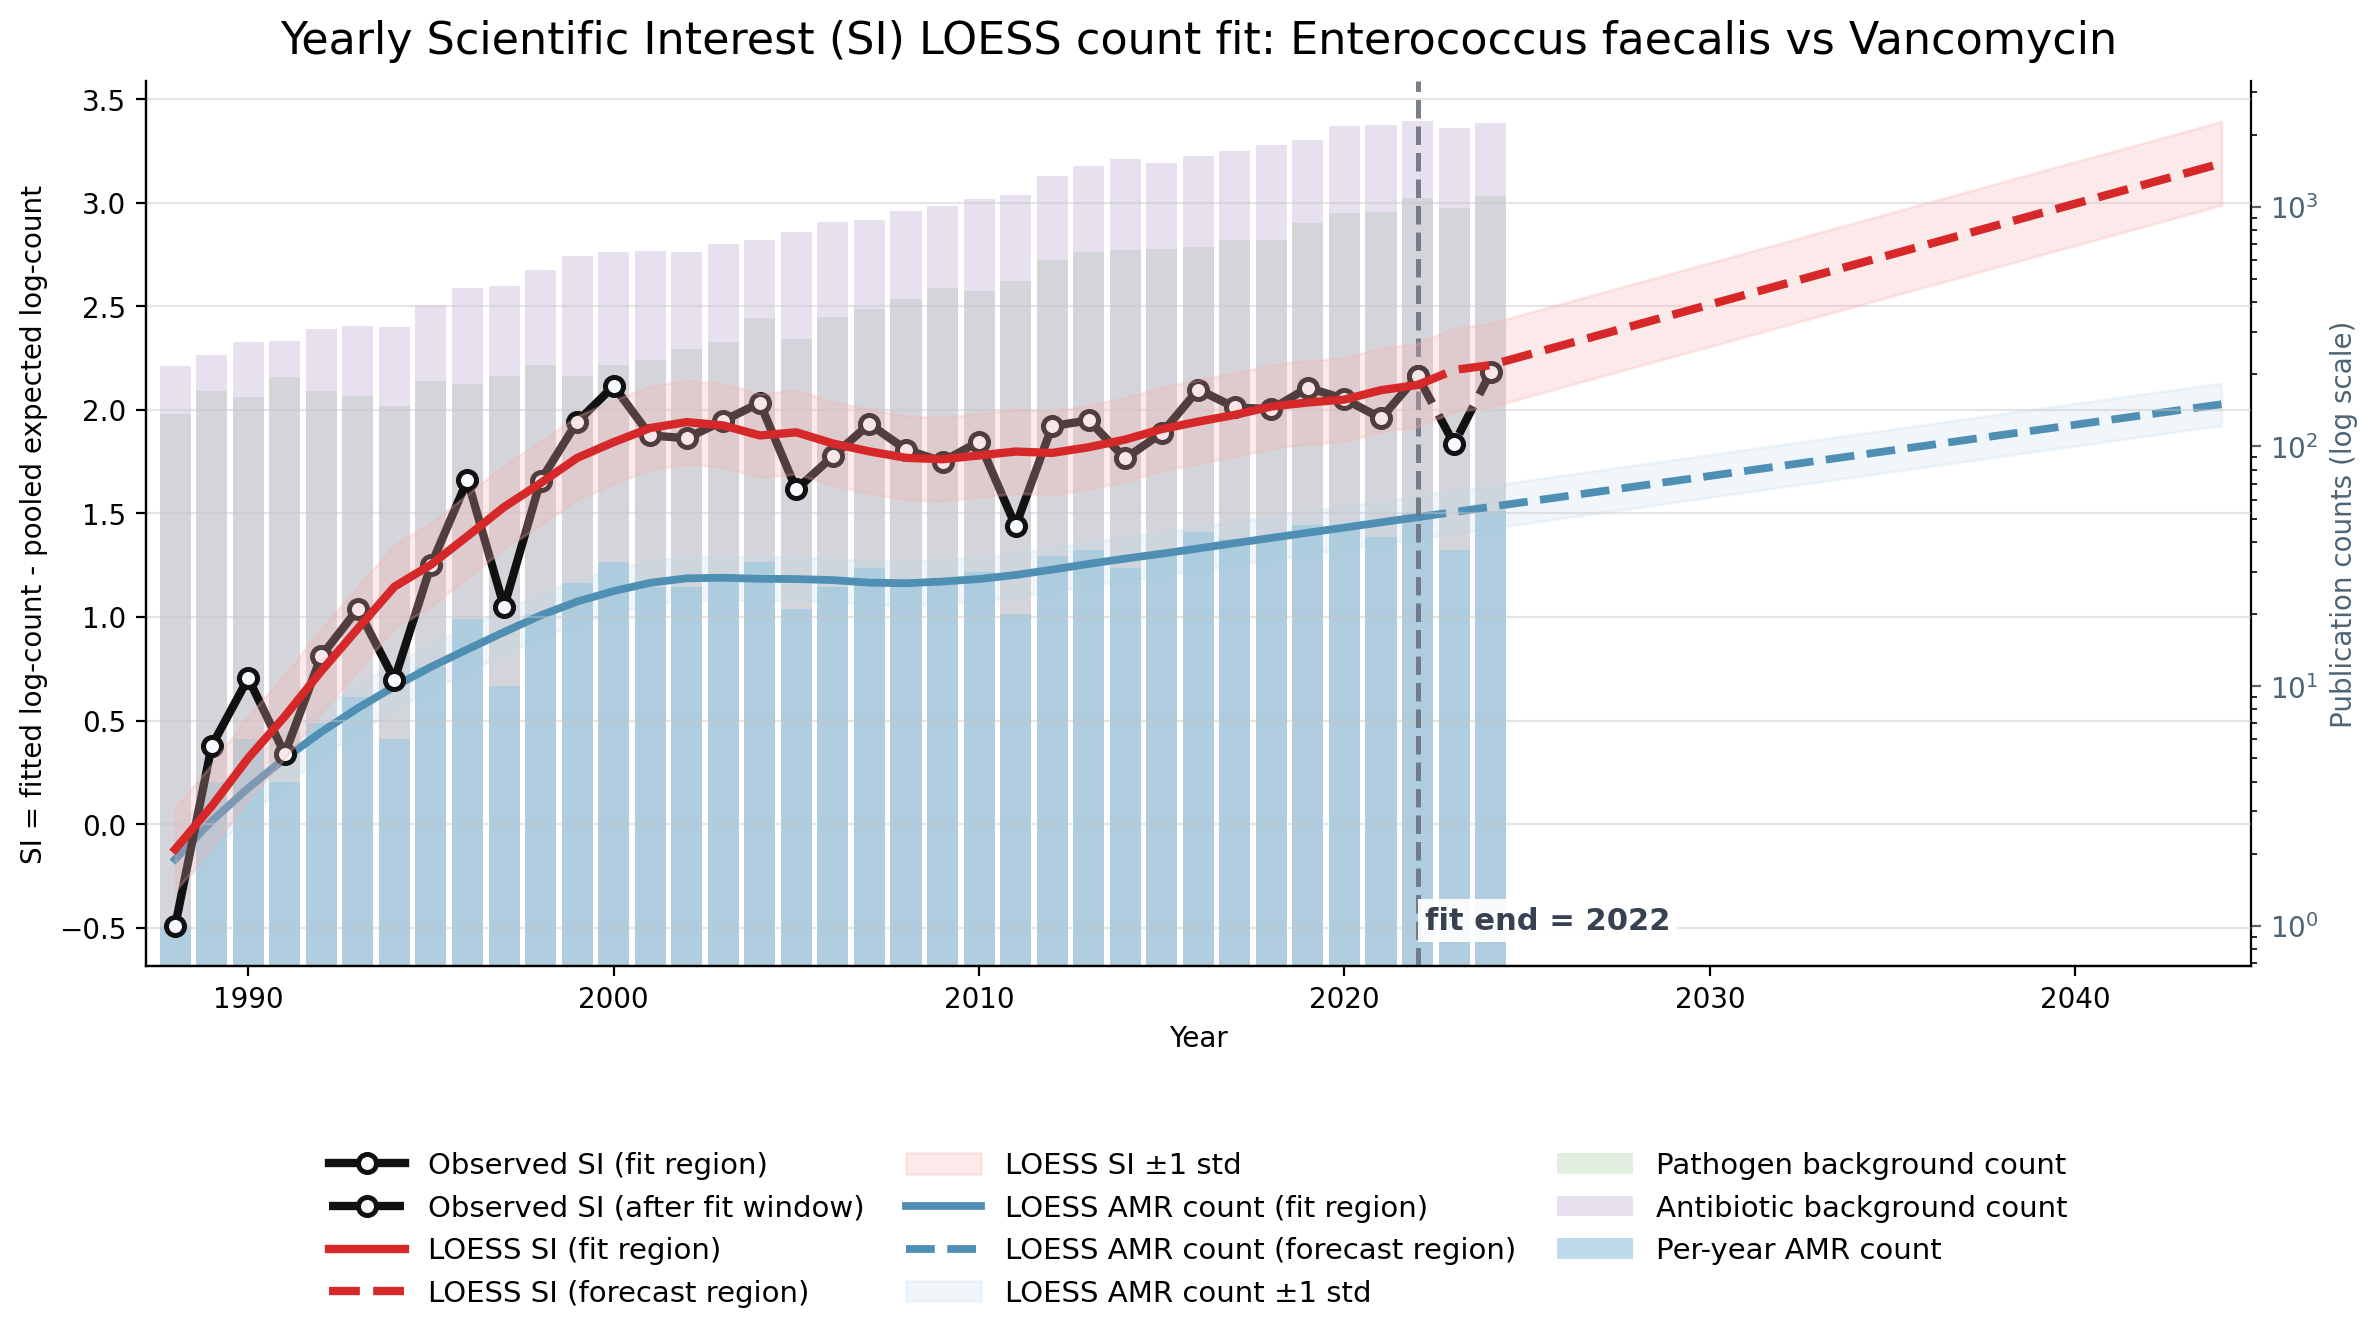

Plotting Staphylococcus aureus vs Oxacillin


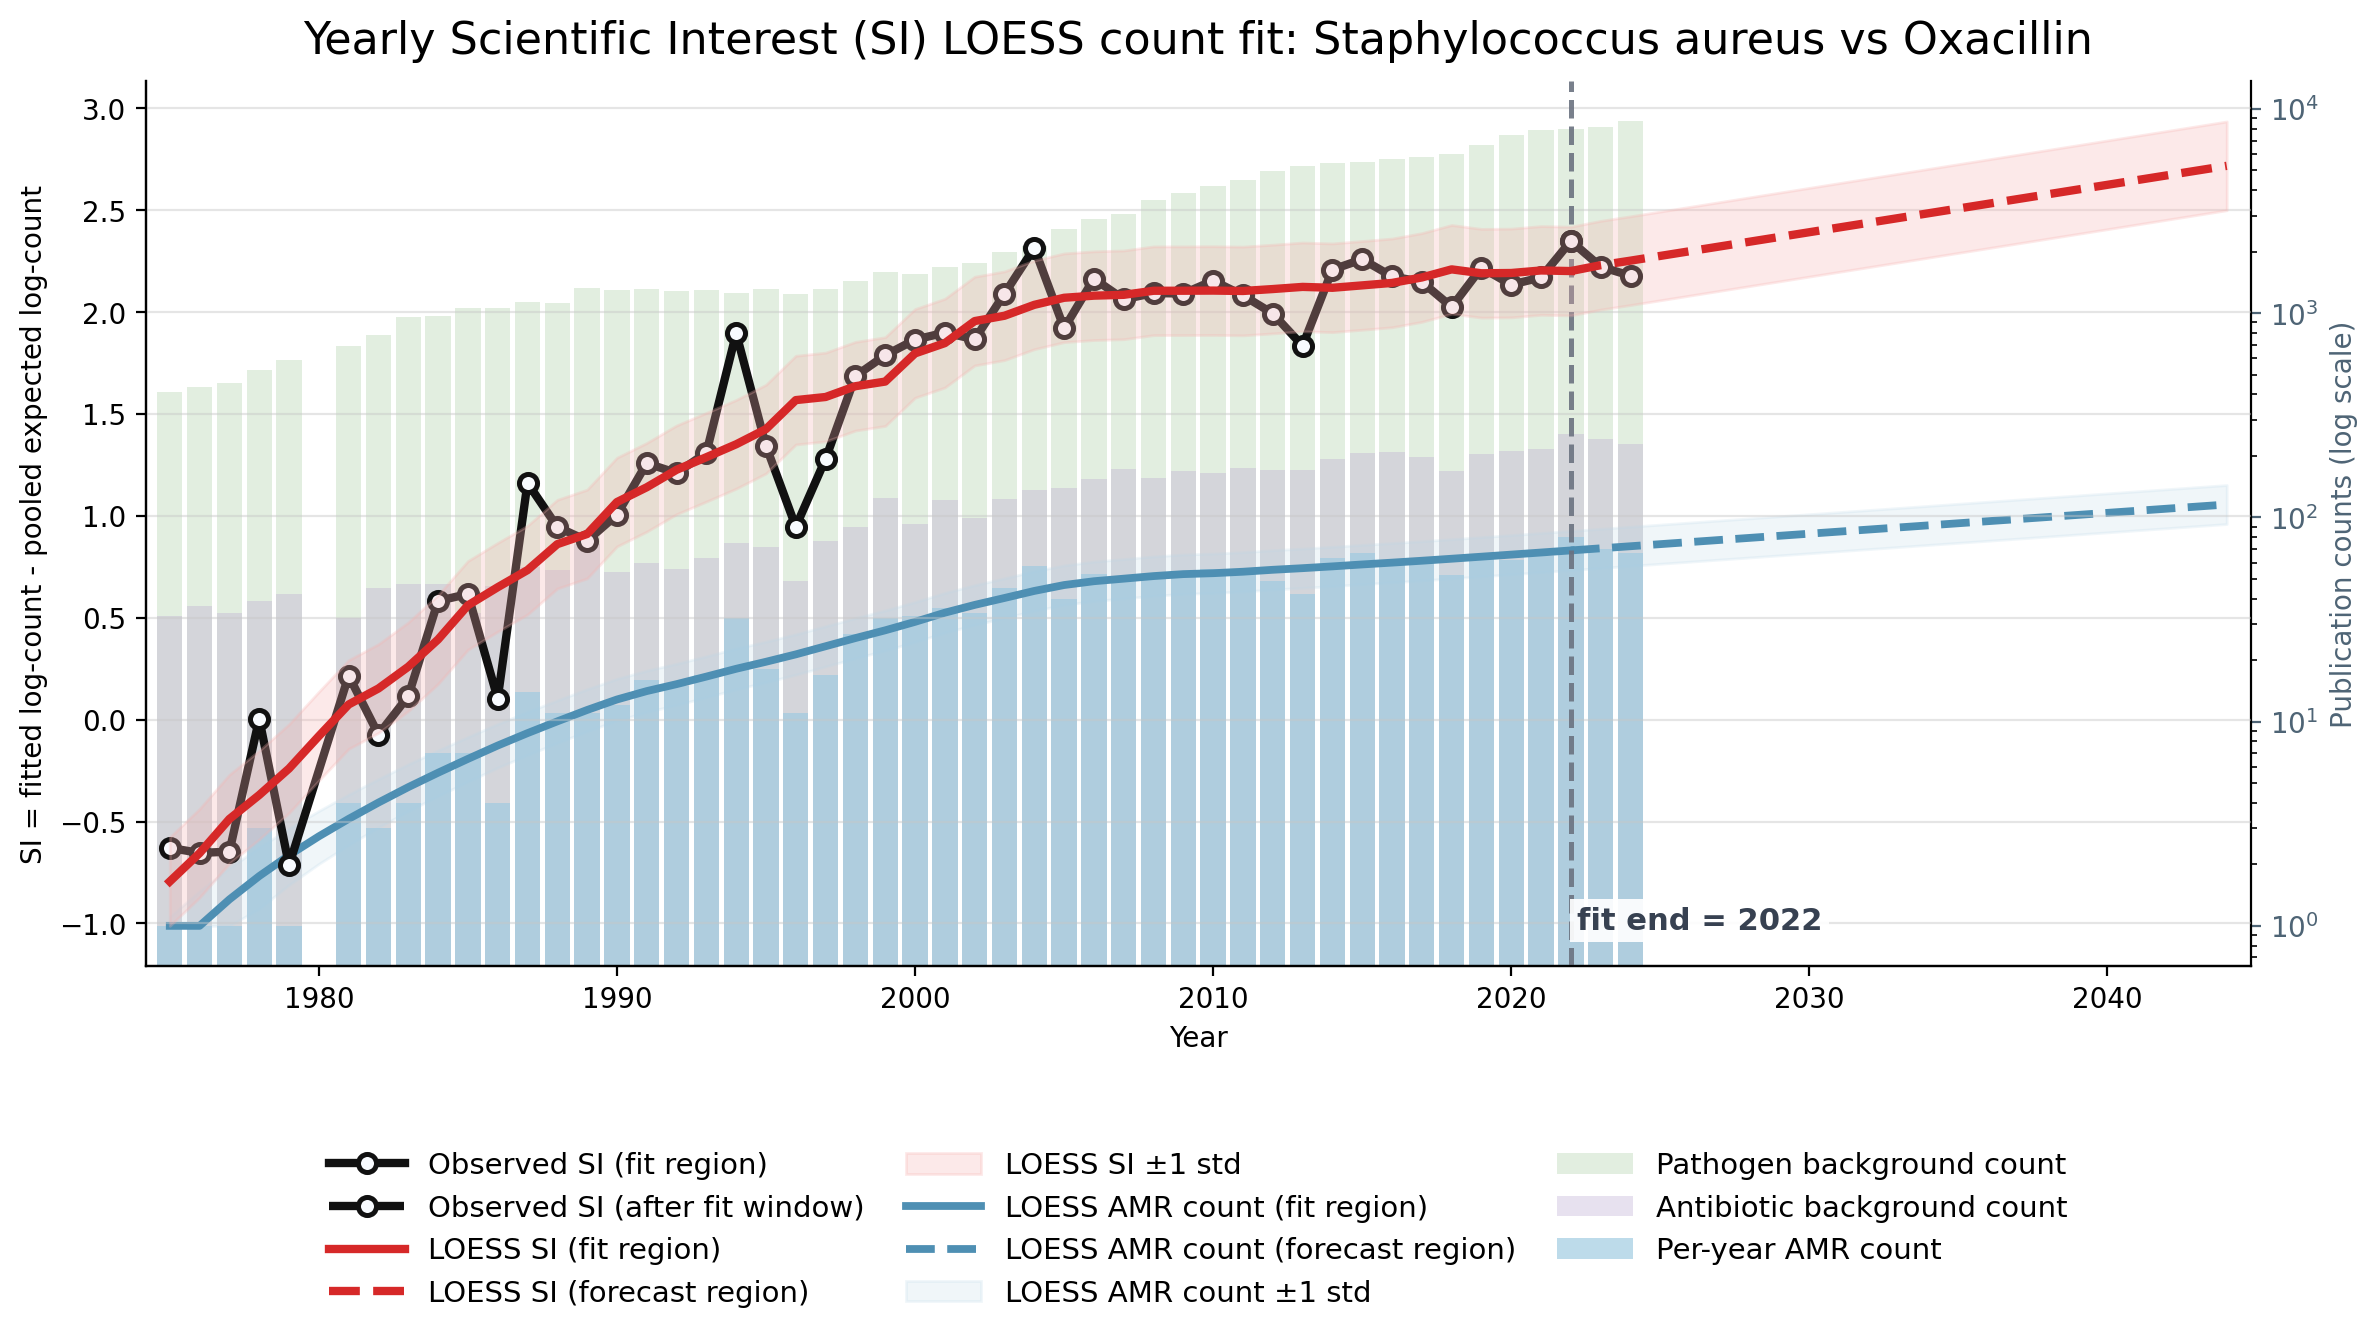

Plotting Escherichia coli vs Tetracycline


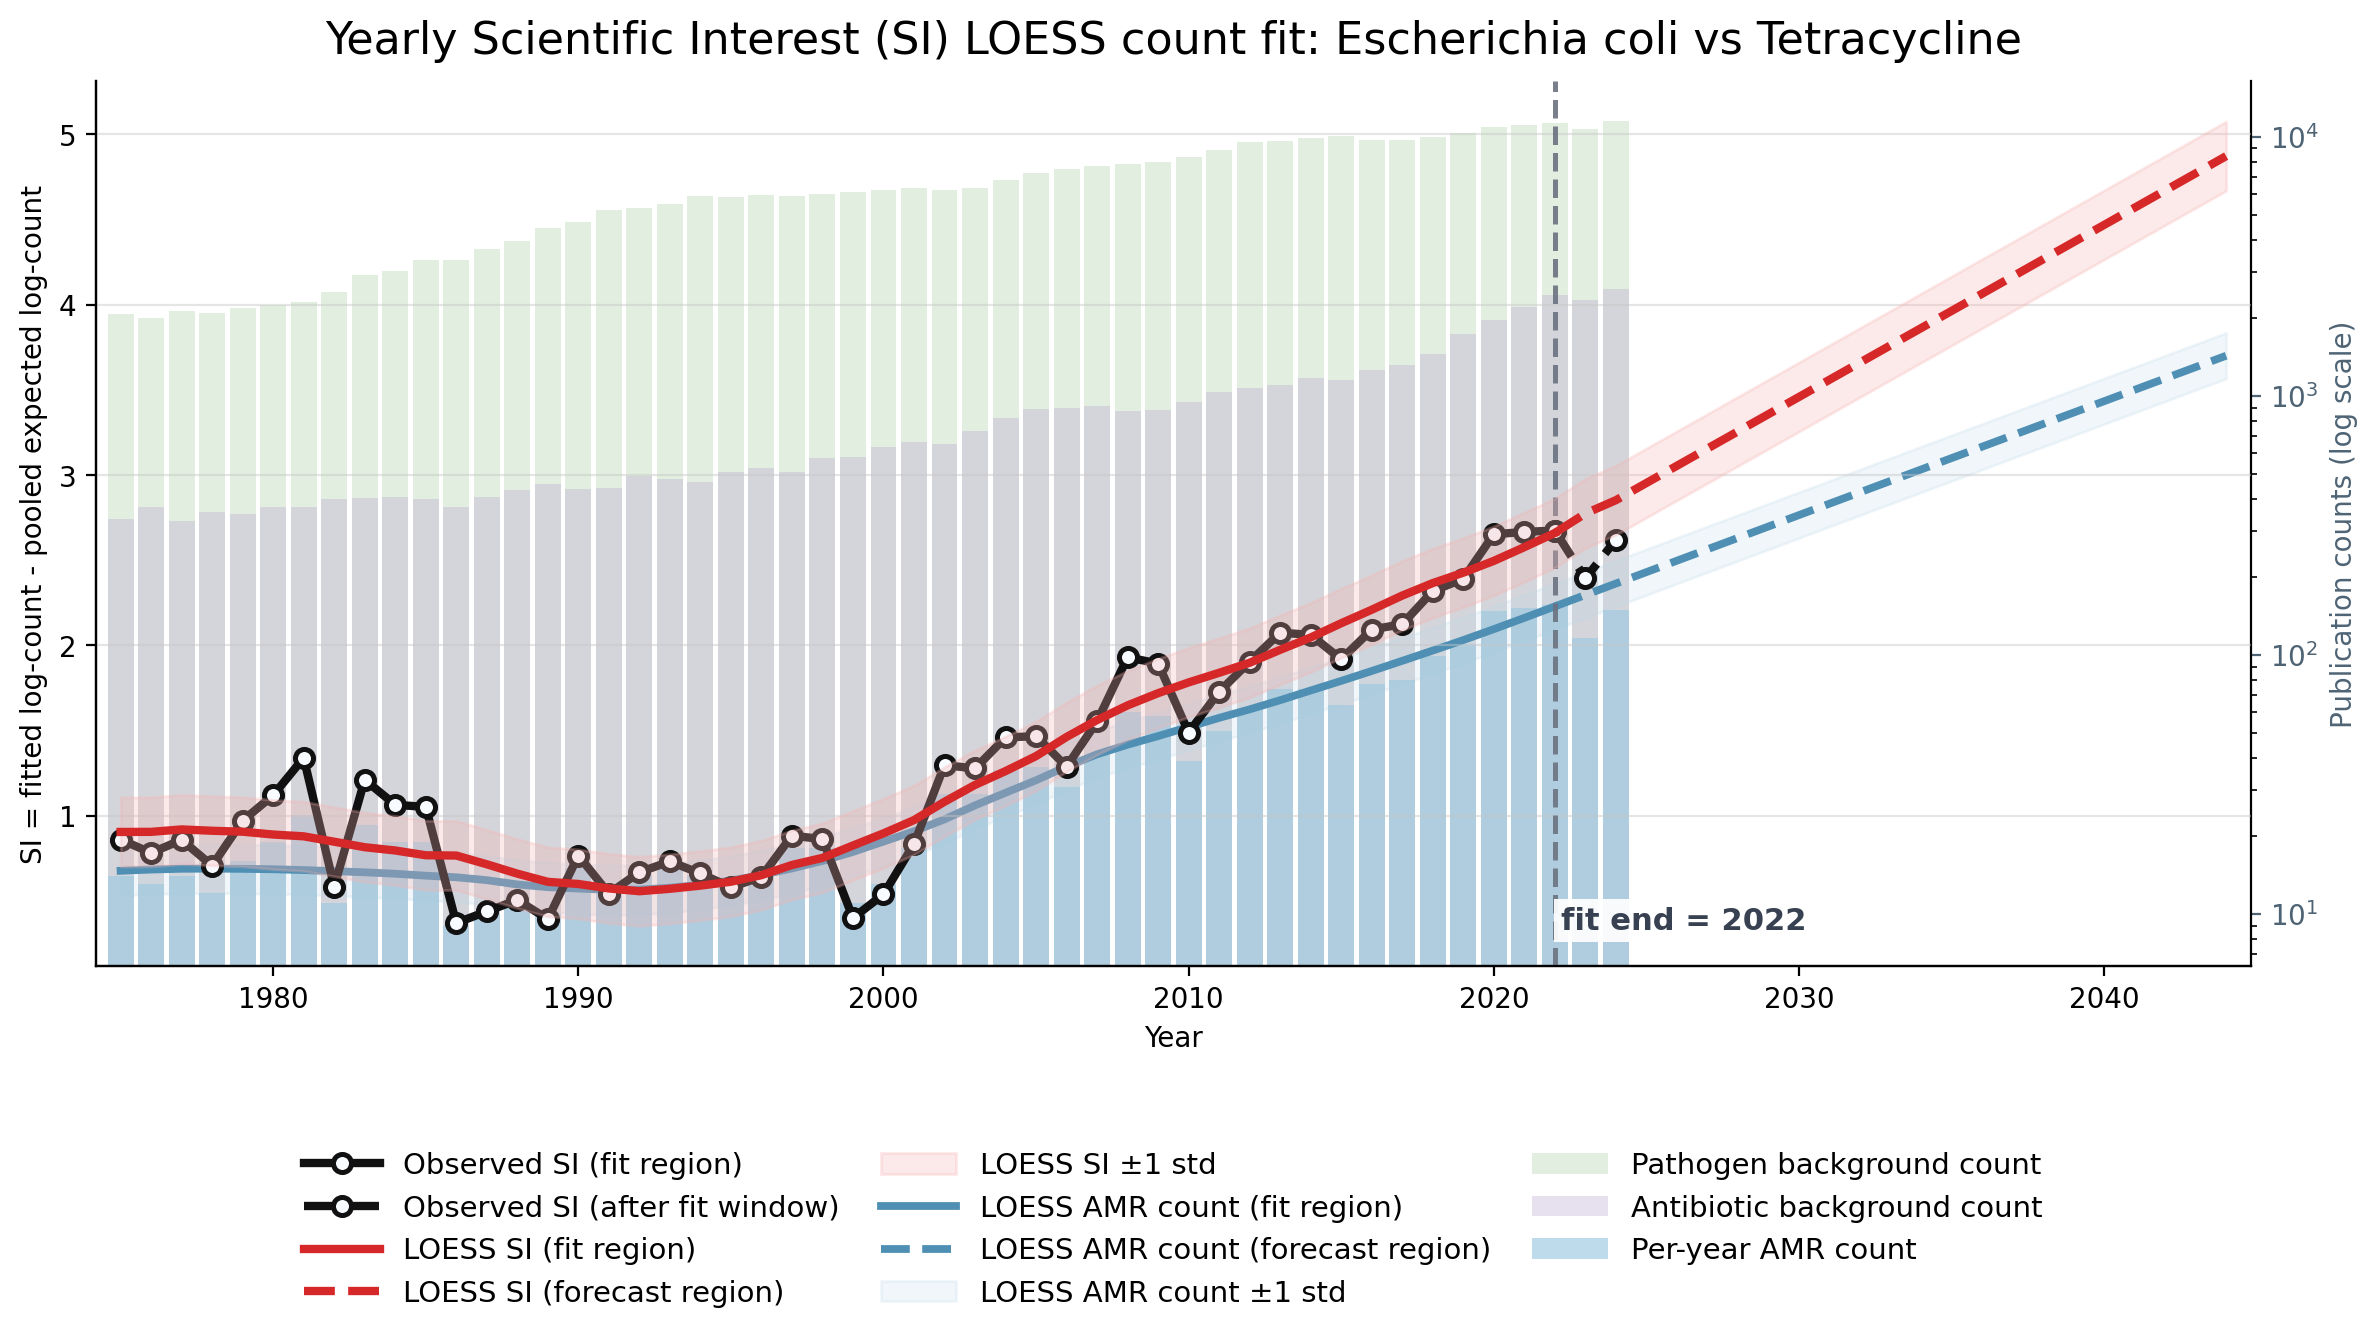

Plotting Klebsiella pneumoniae vs Colistin


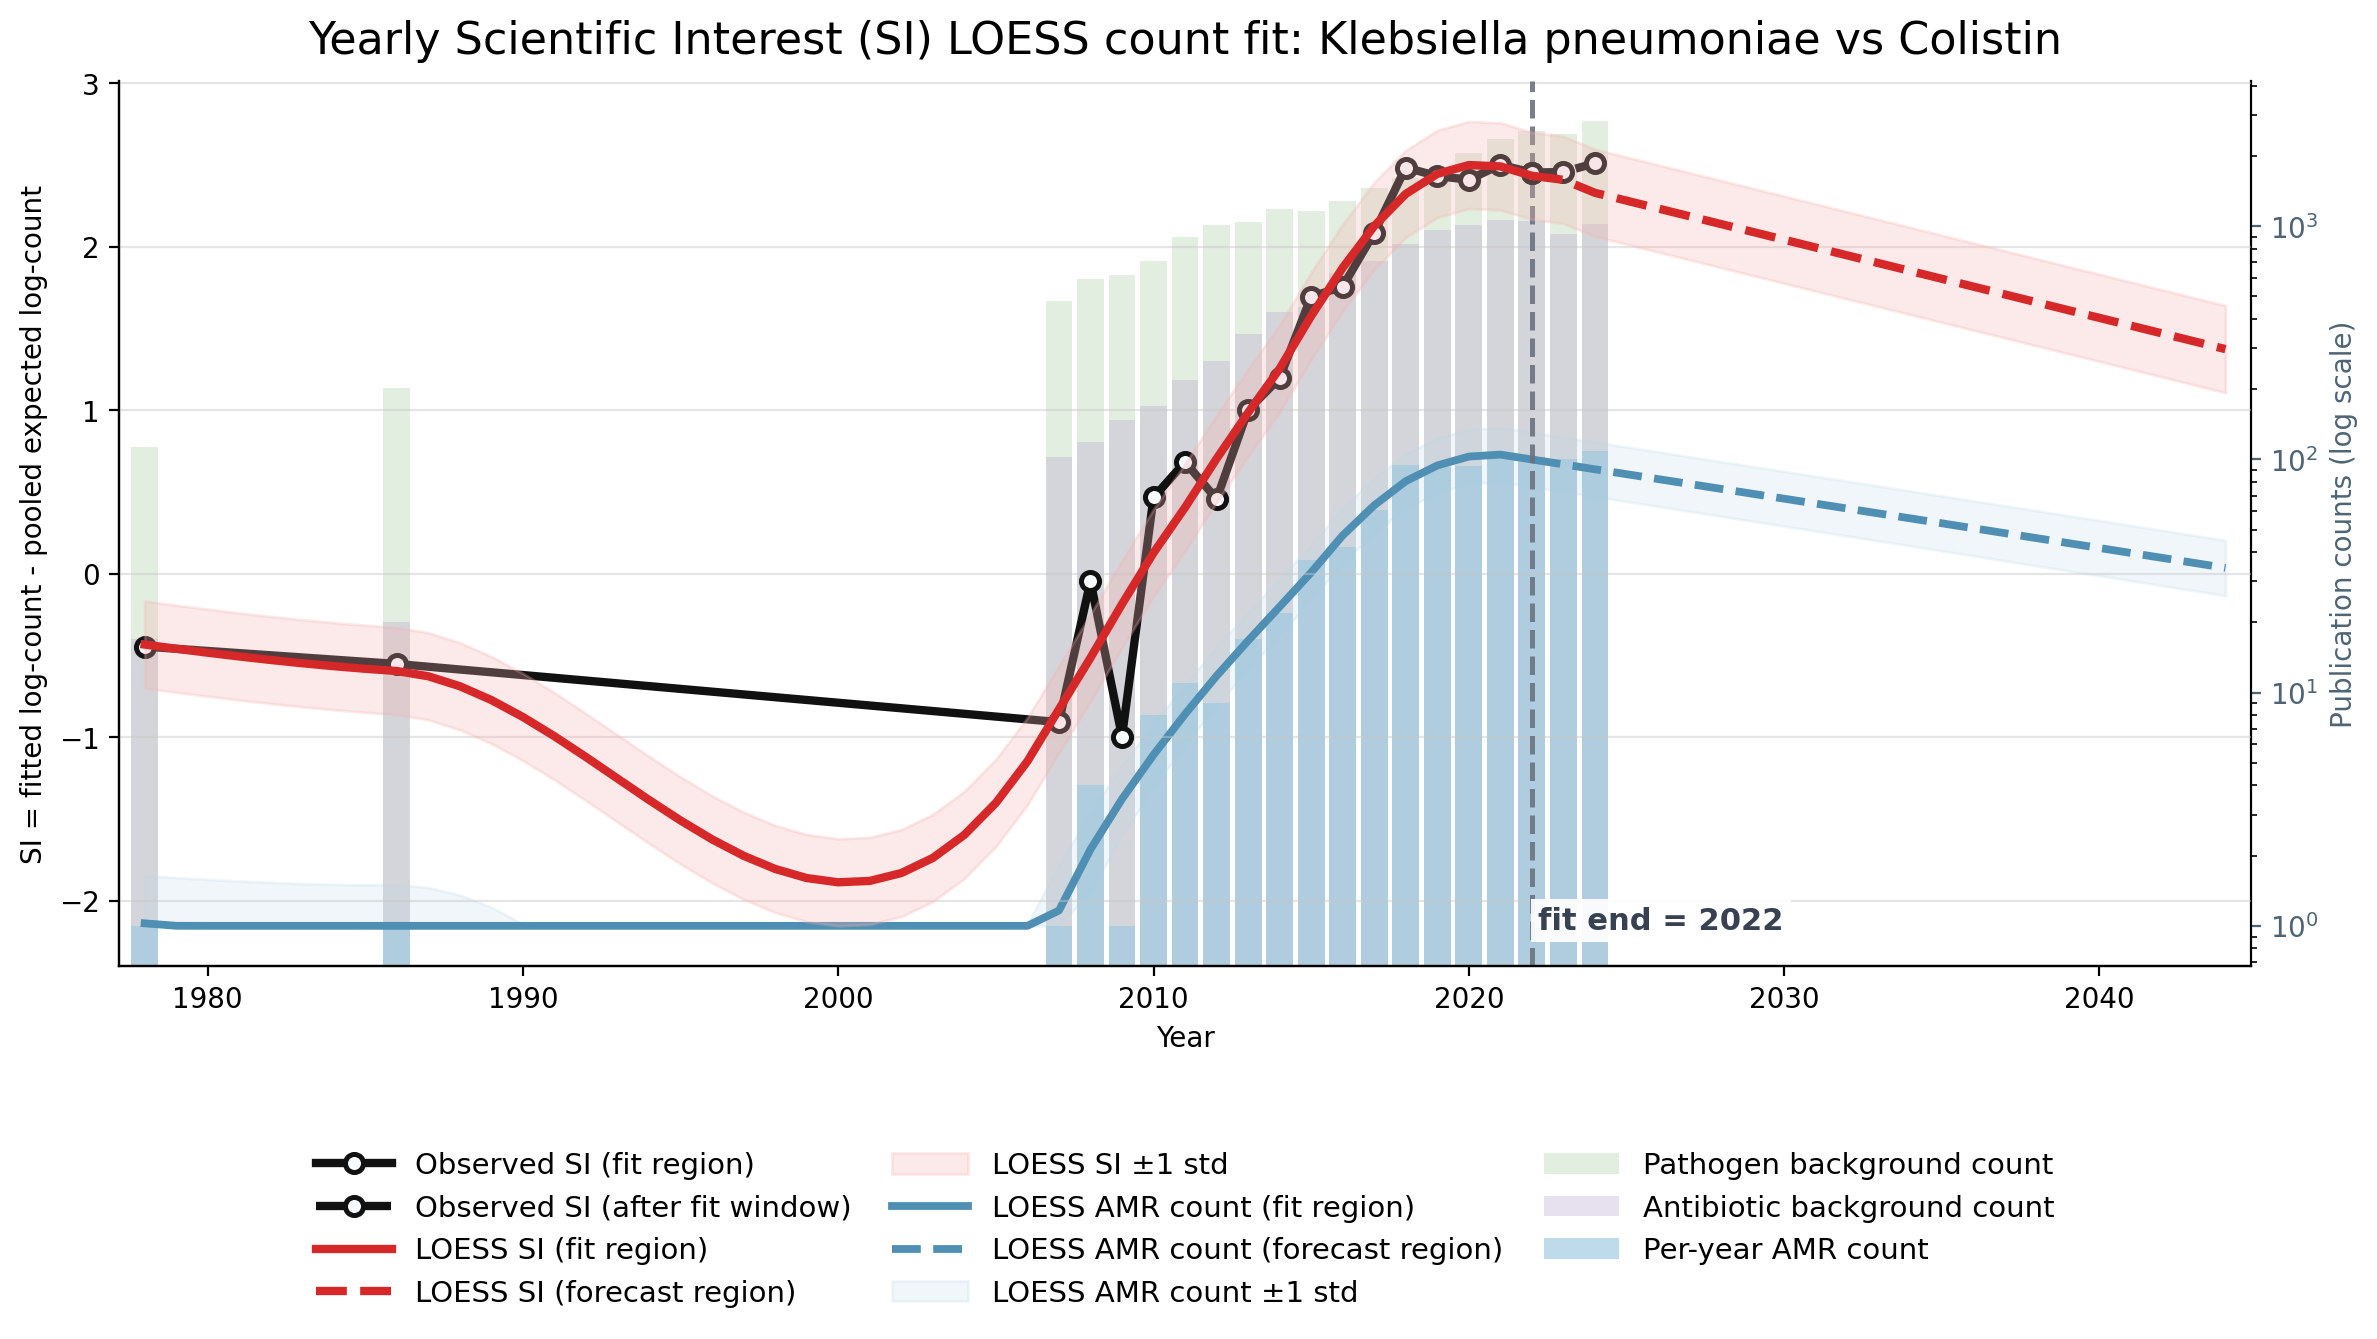

Plotting Haemophilus influenzae vs Ampicillin


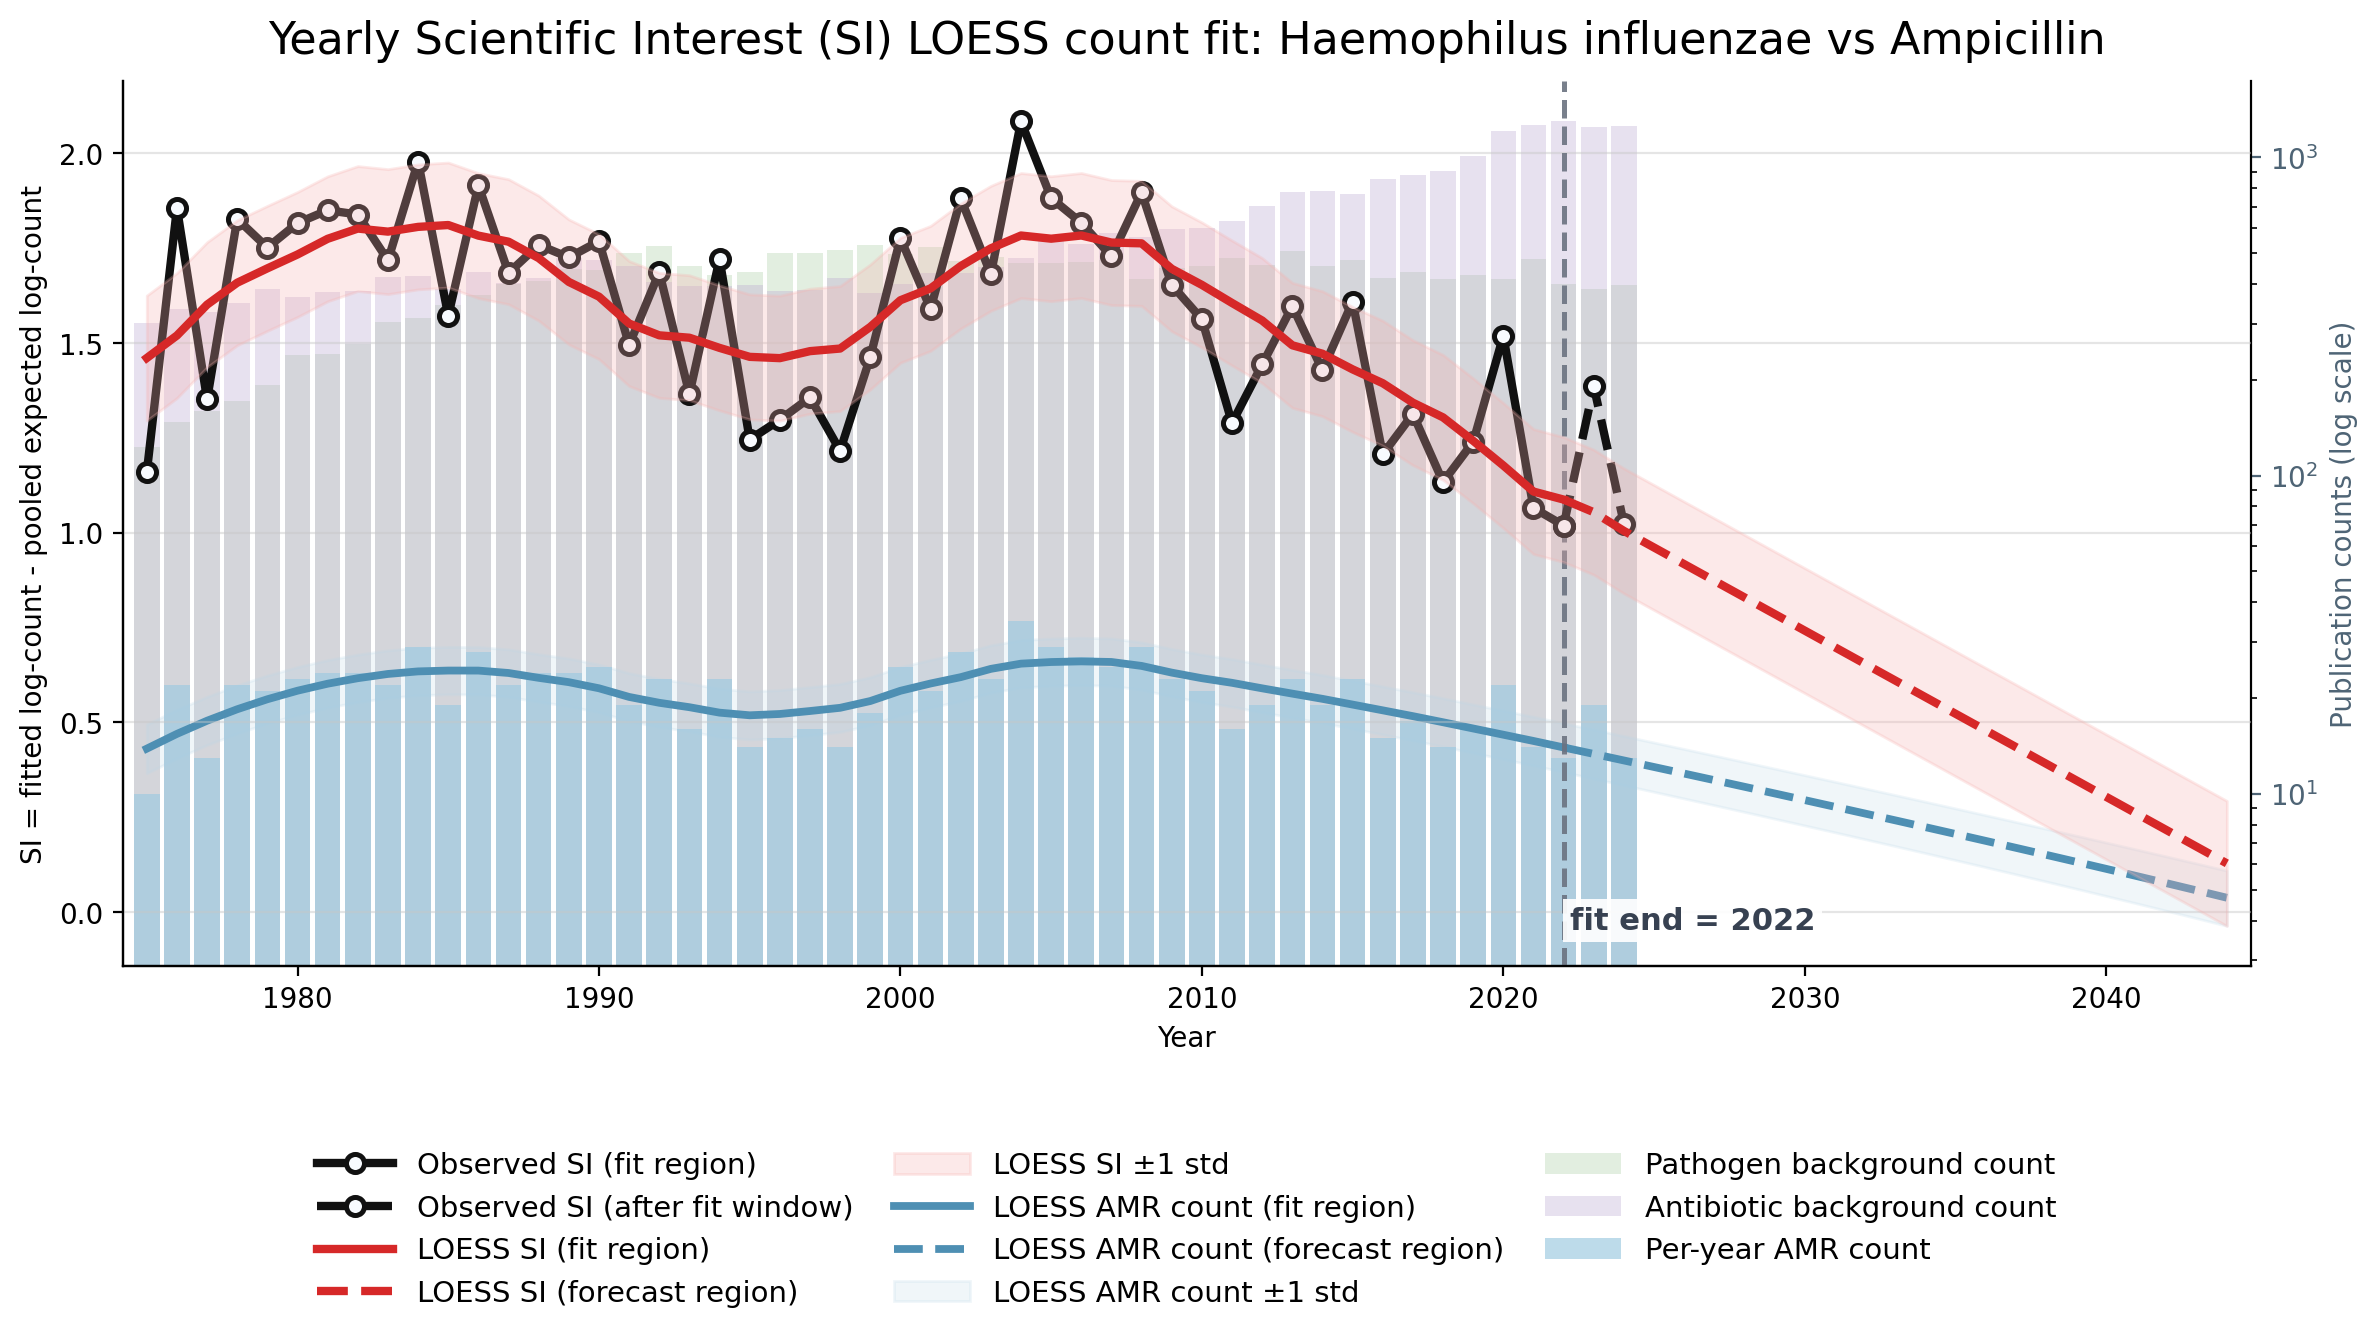

Plotting Acinetobacter baumannii vs Colistin


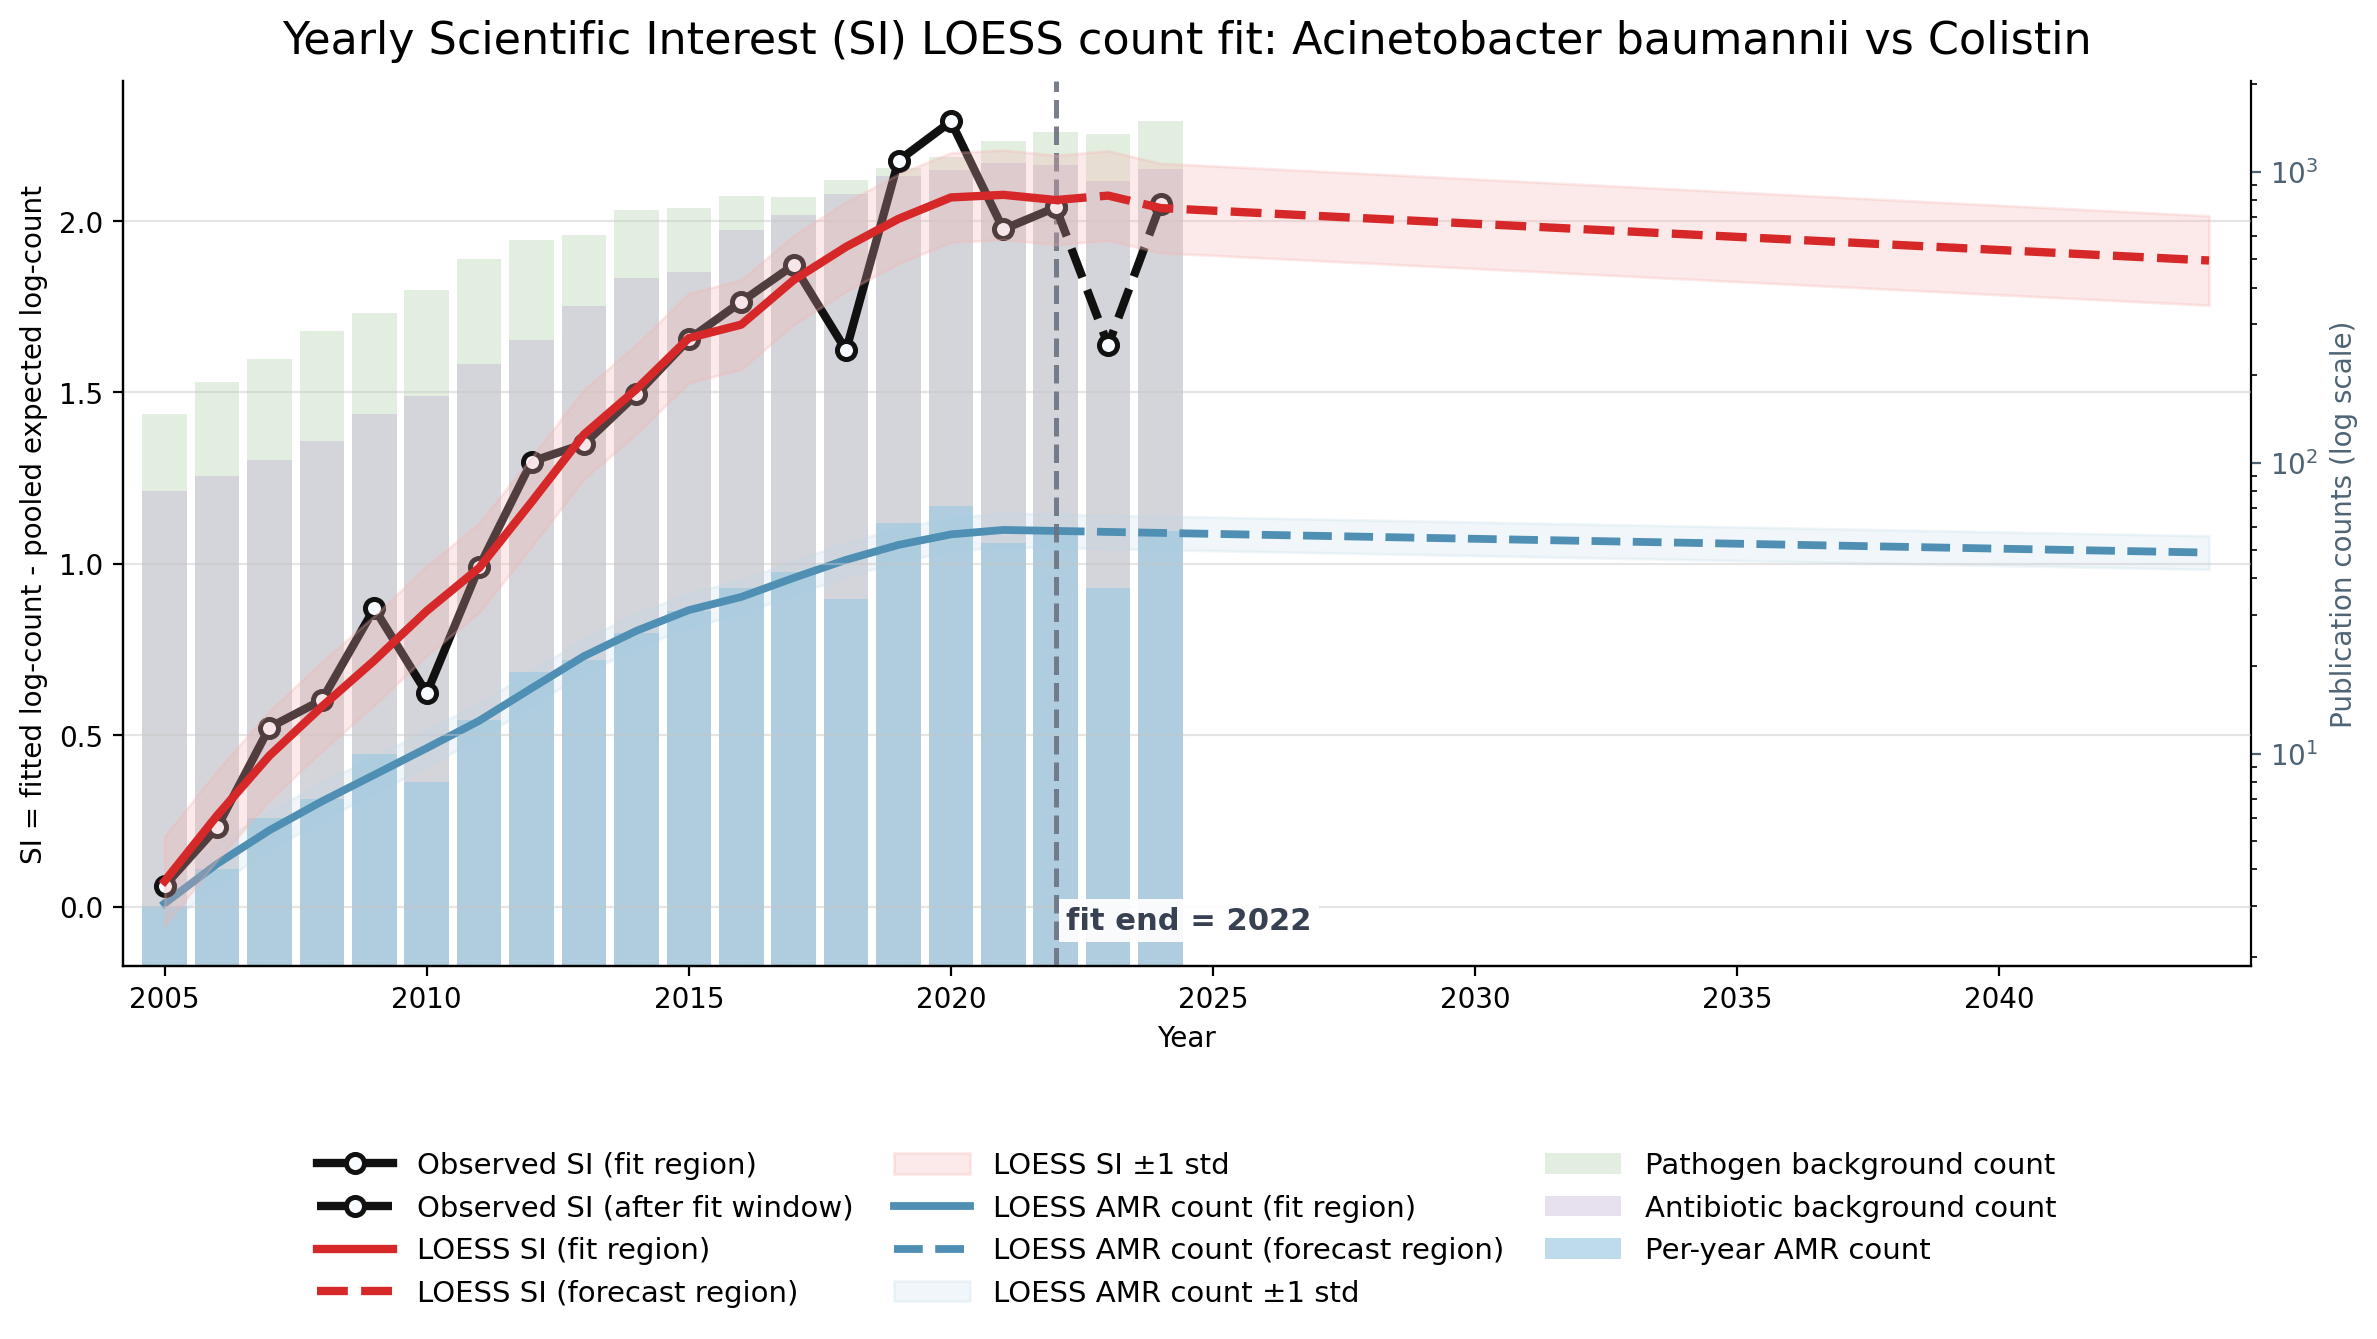

Plotting Staphylococcus aureus vs Erythromycin


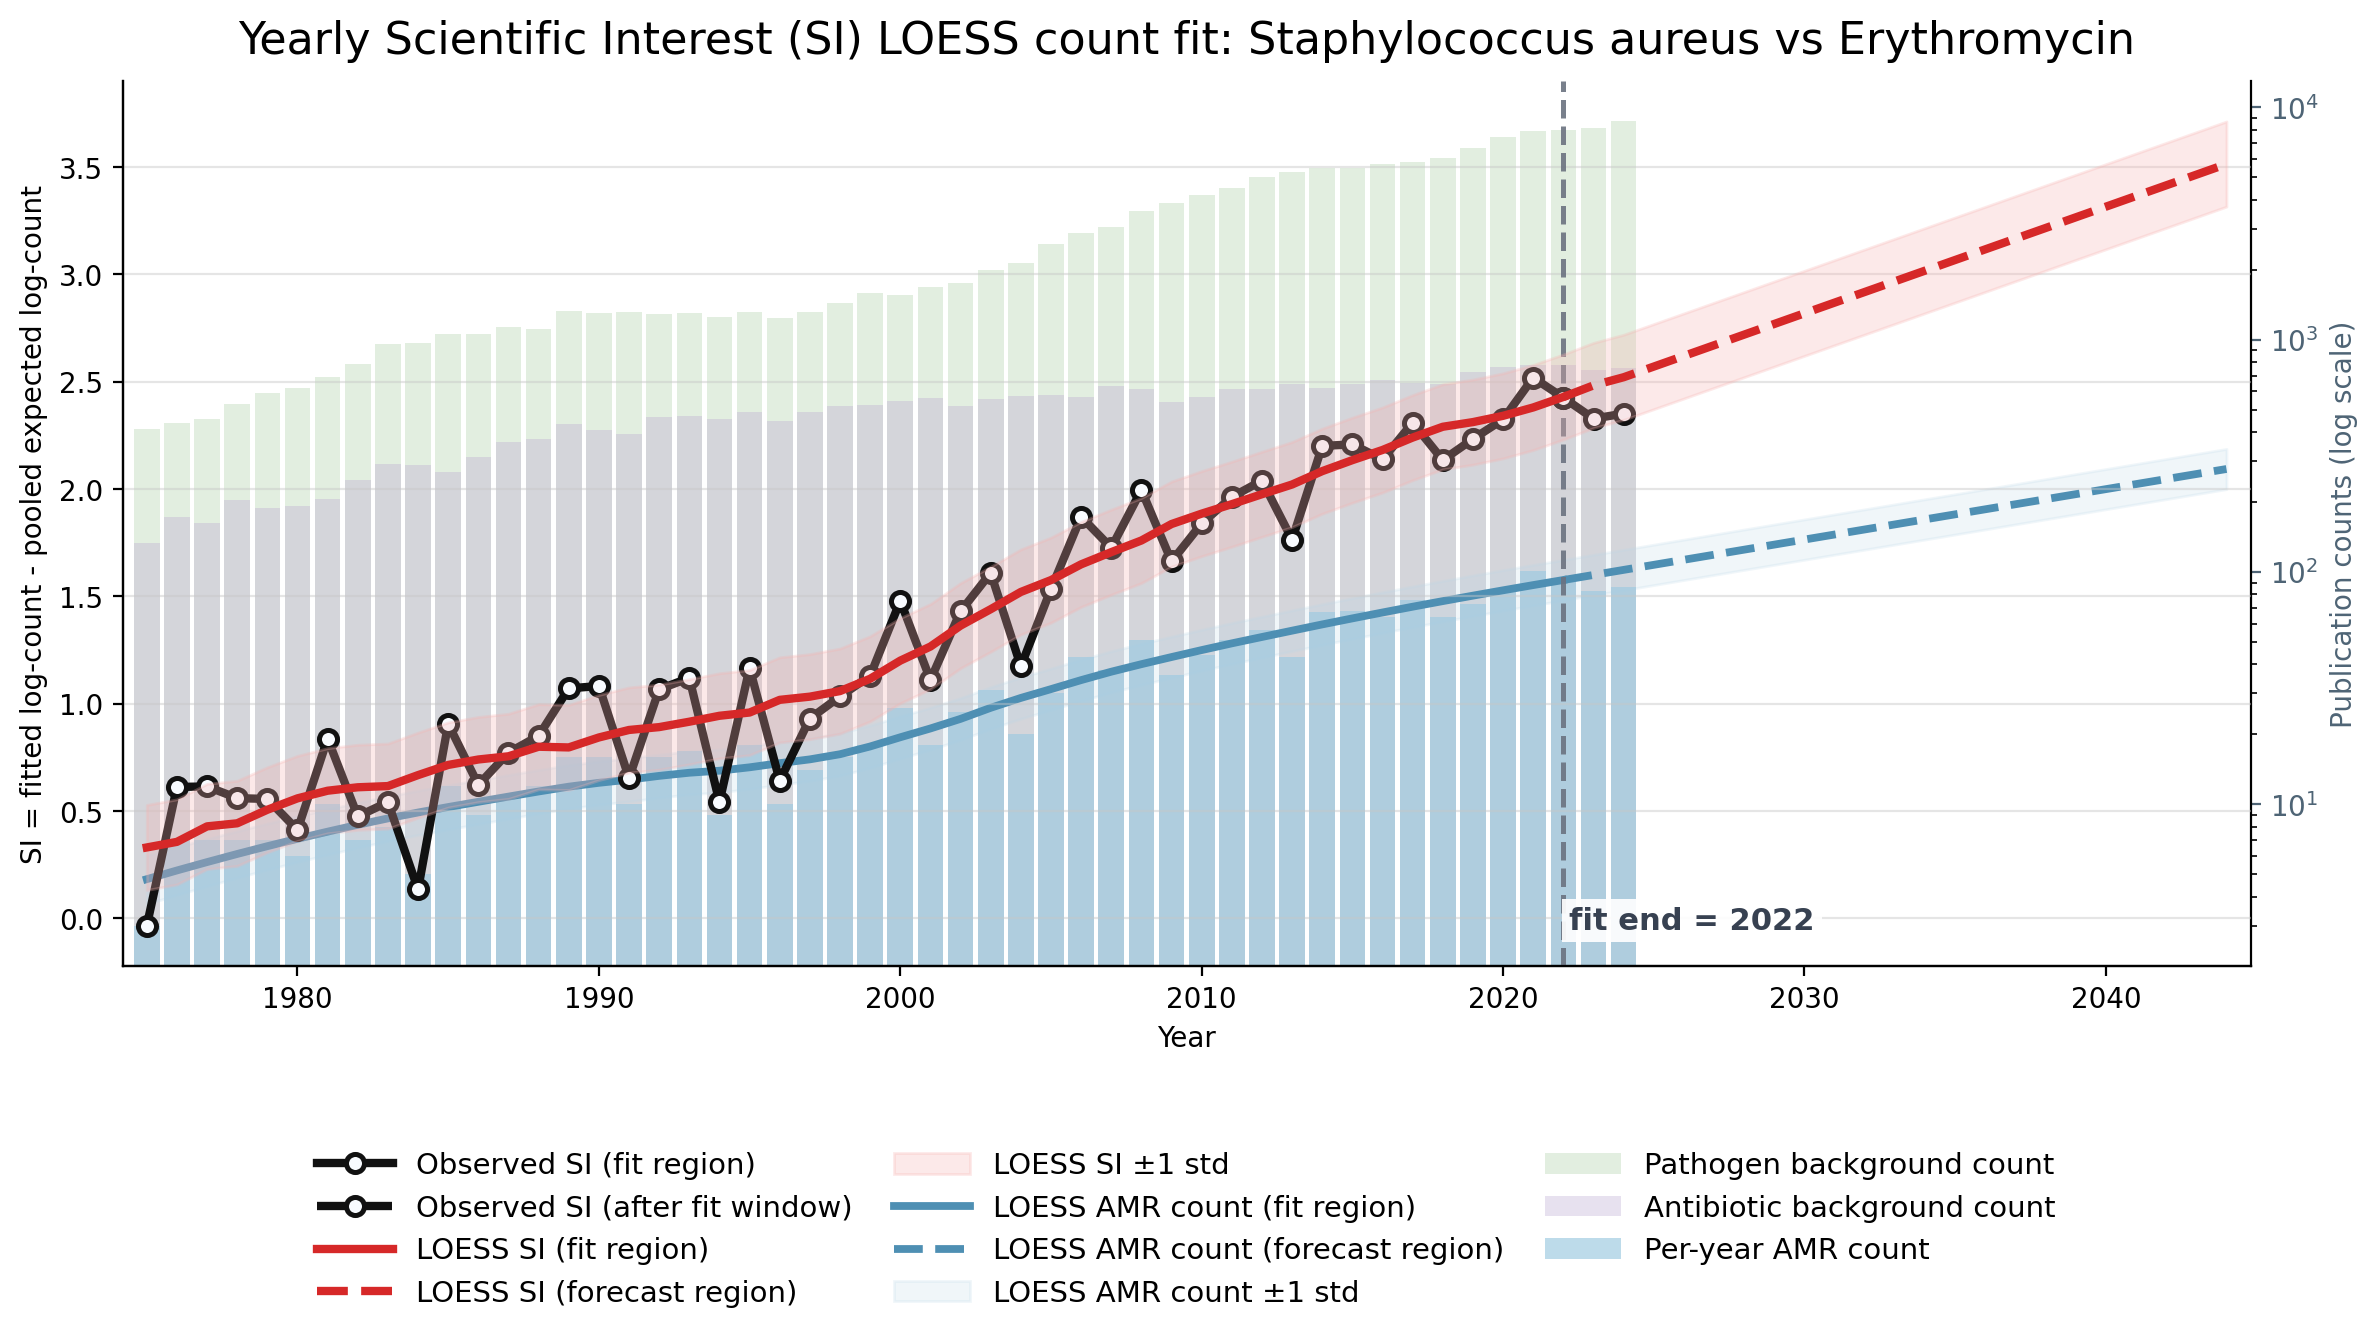

Plotting Escherichia coli vs Trimethoprim


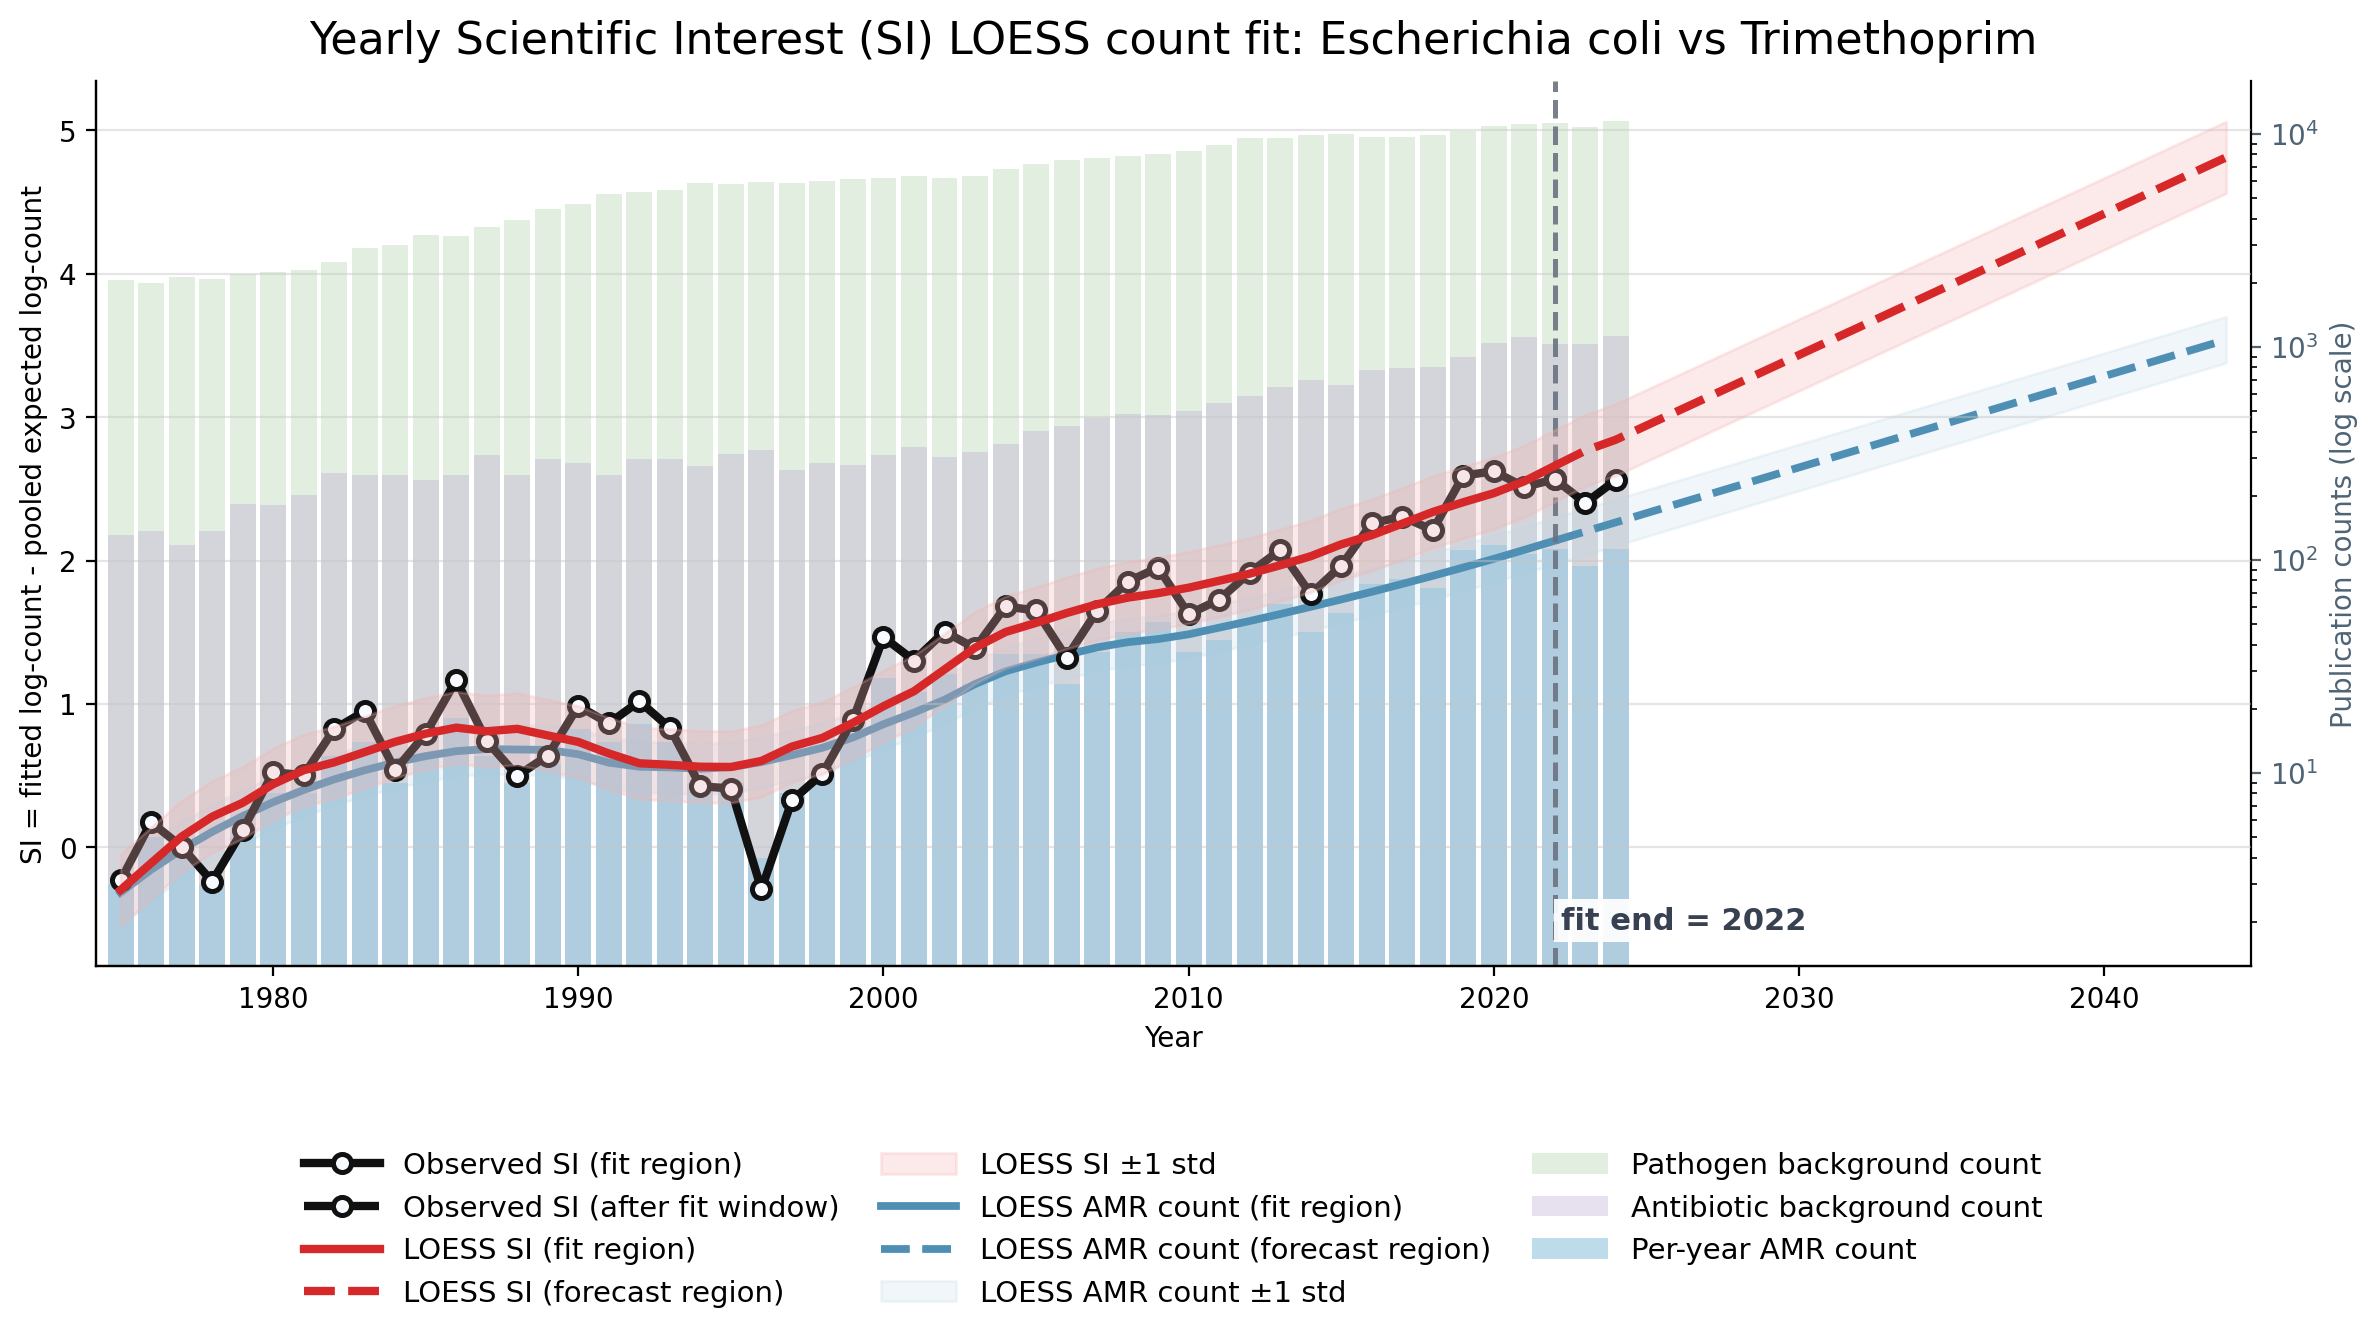

Plotting Lactococcus lactis vs Sulfathiazole
Skipping Lactococcus lactis vs Sulfathiazole: Need at least 3 observed years between 1970 and 2022; found 1.
Plotting Pseudomonas aeruginosa vs Ciprofloxacin


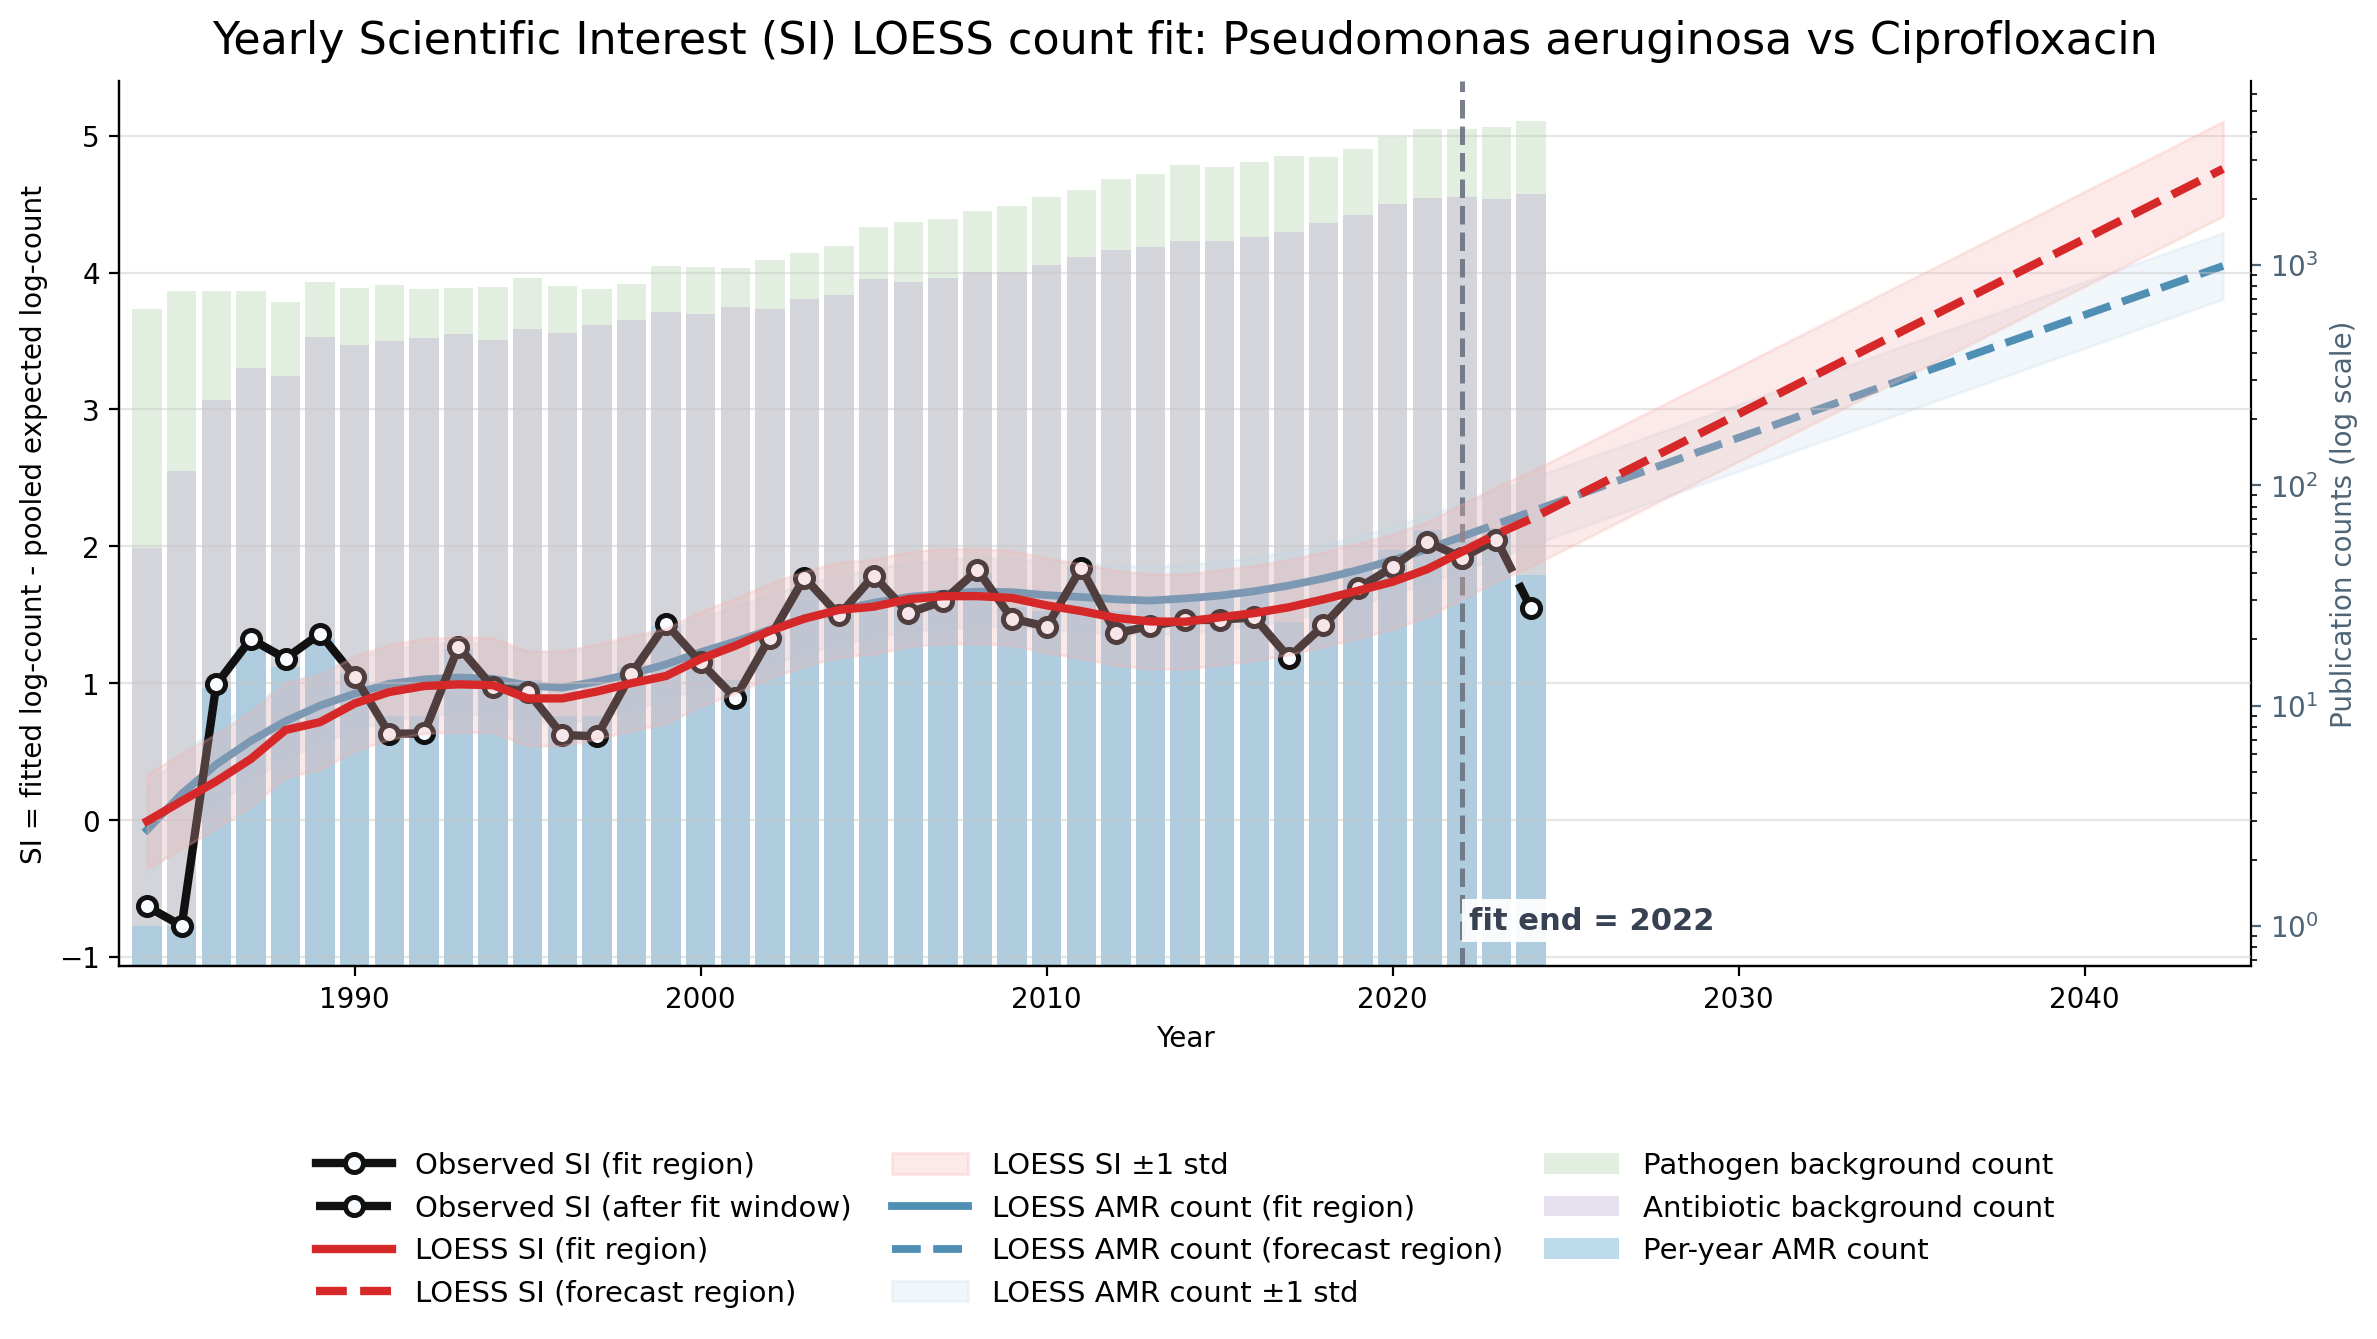

Plotting Streptococcus pneumoniae vs Erythromycin


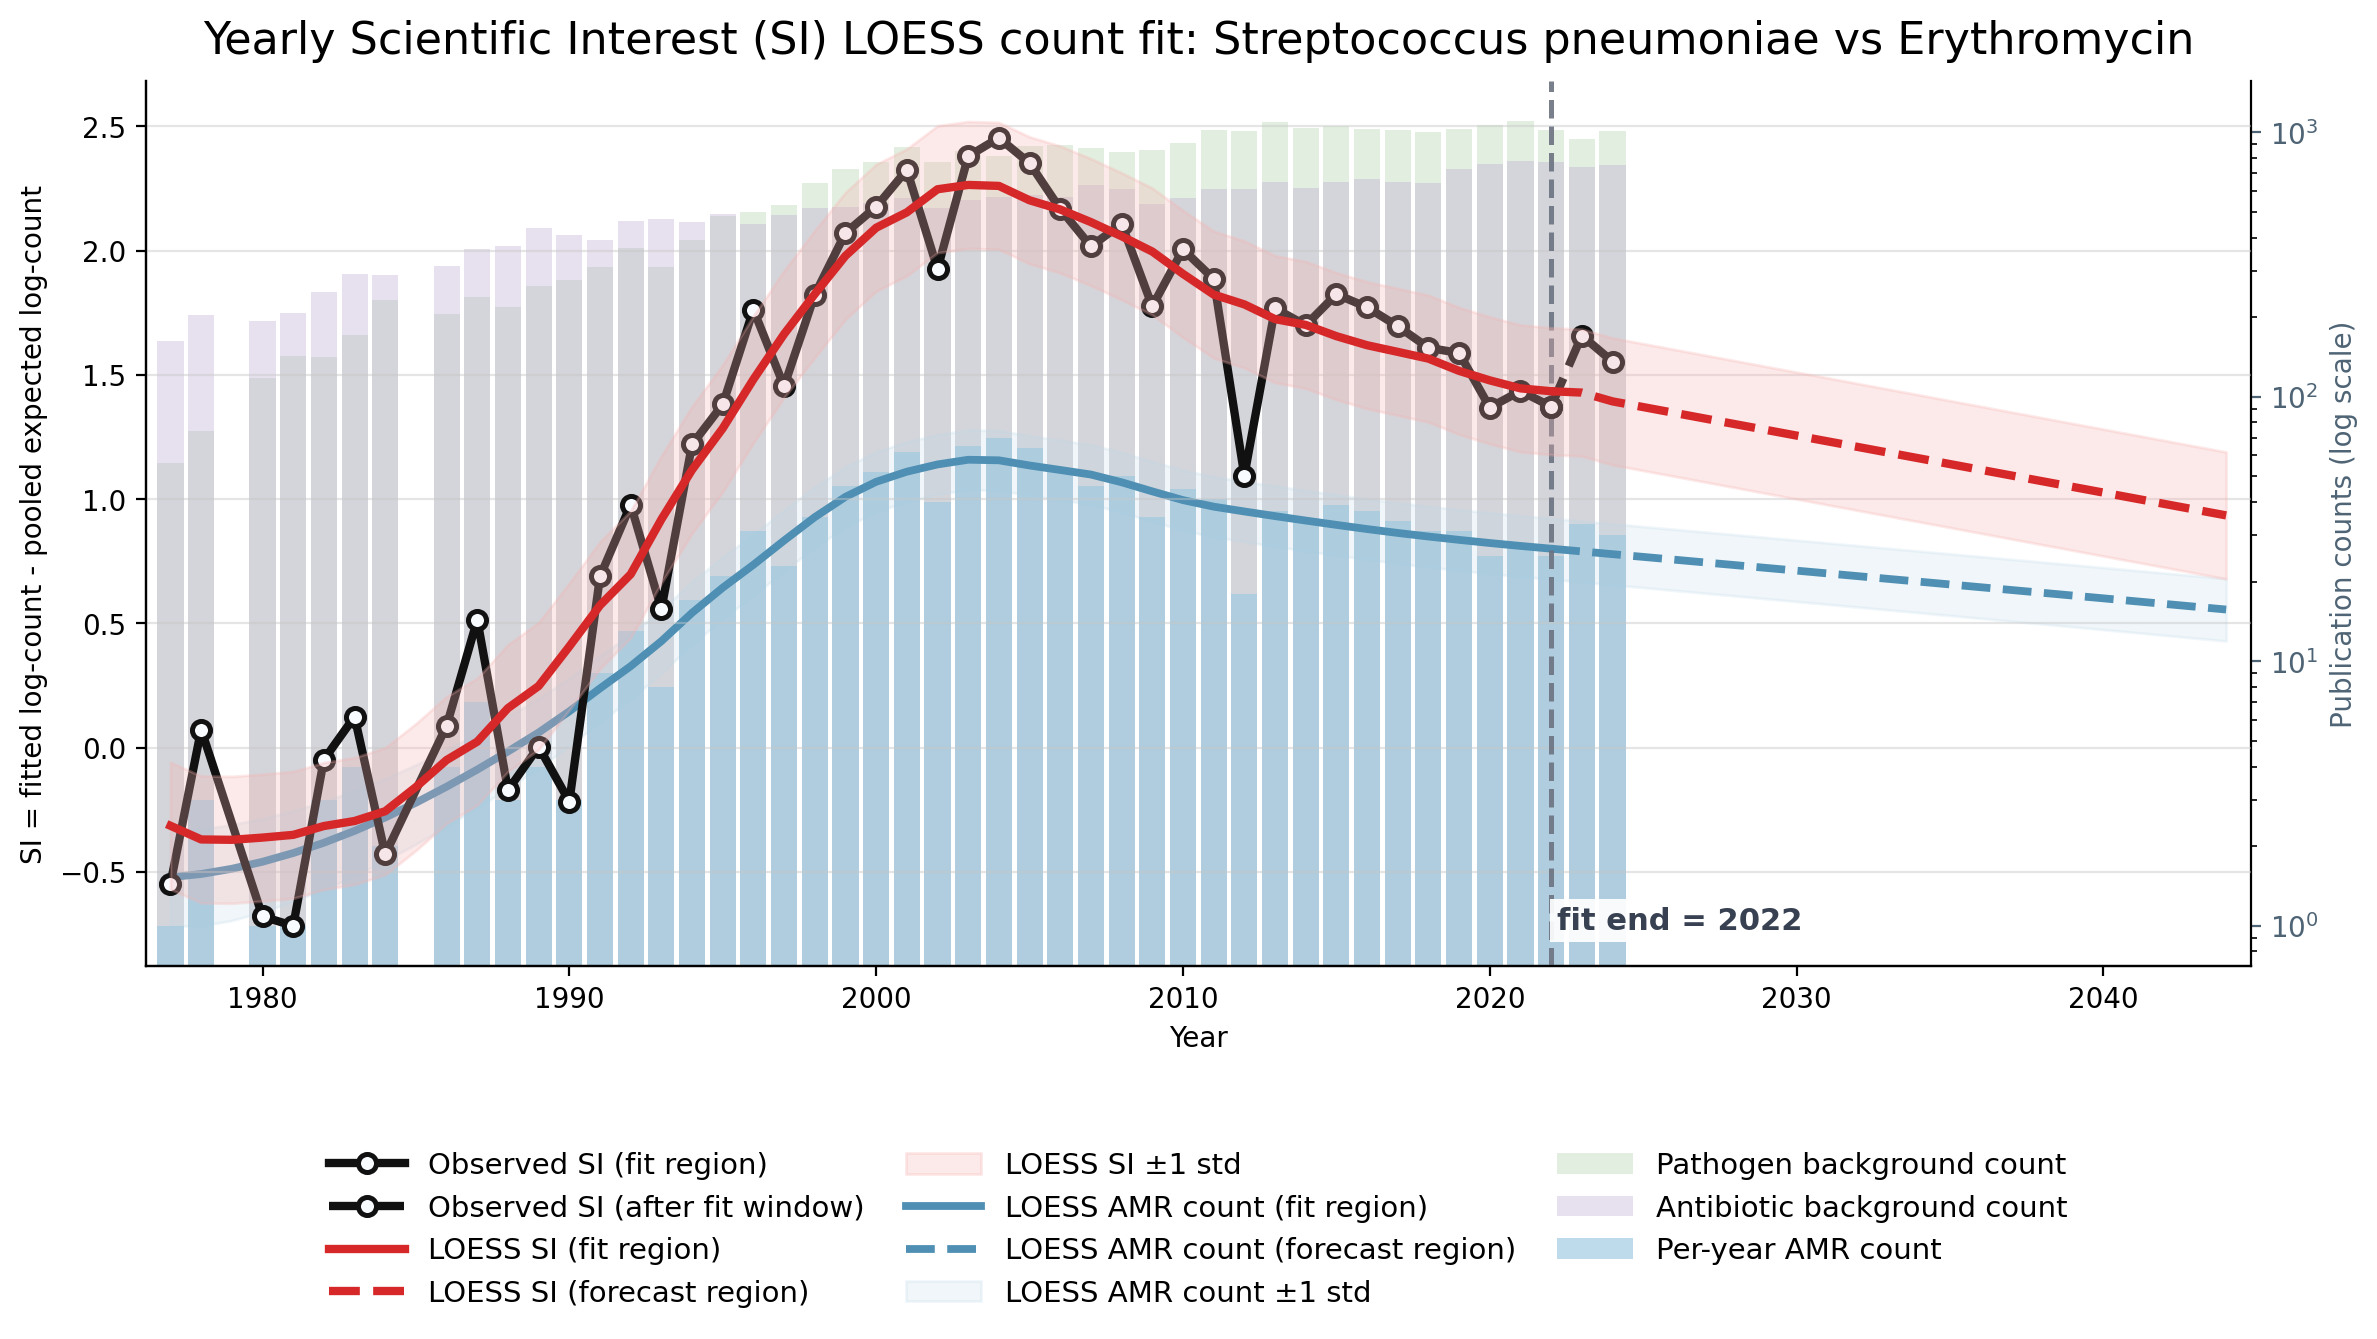

Plotting Staphylococcus aureus vs Ciprofloxacin


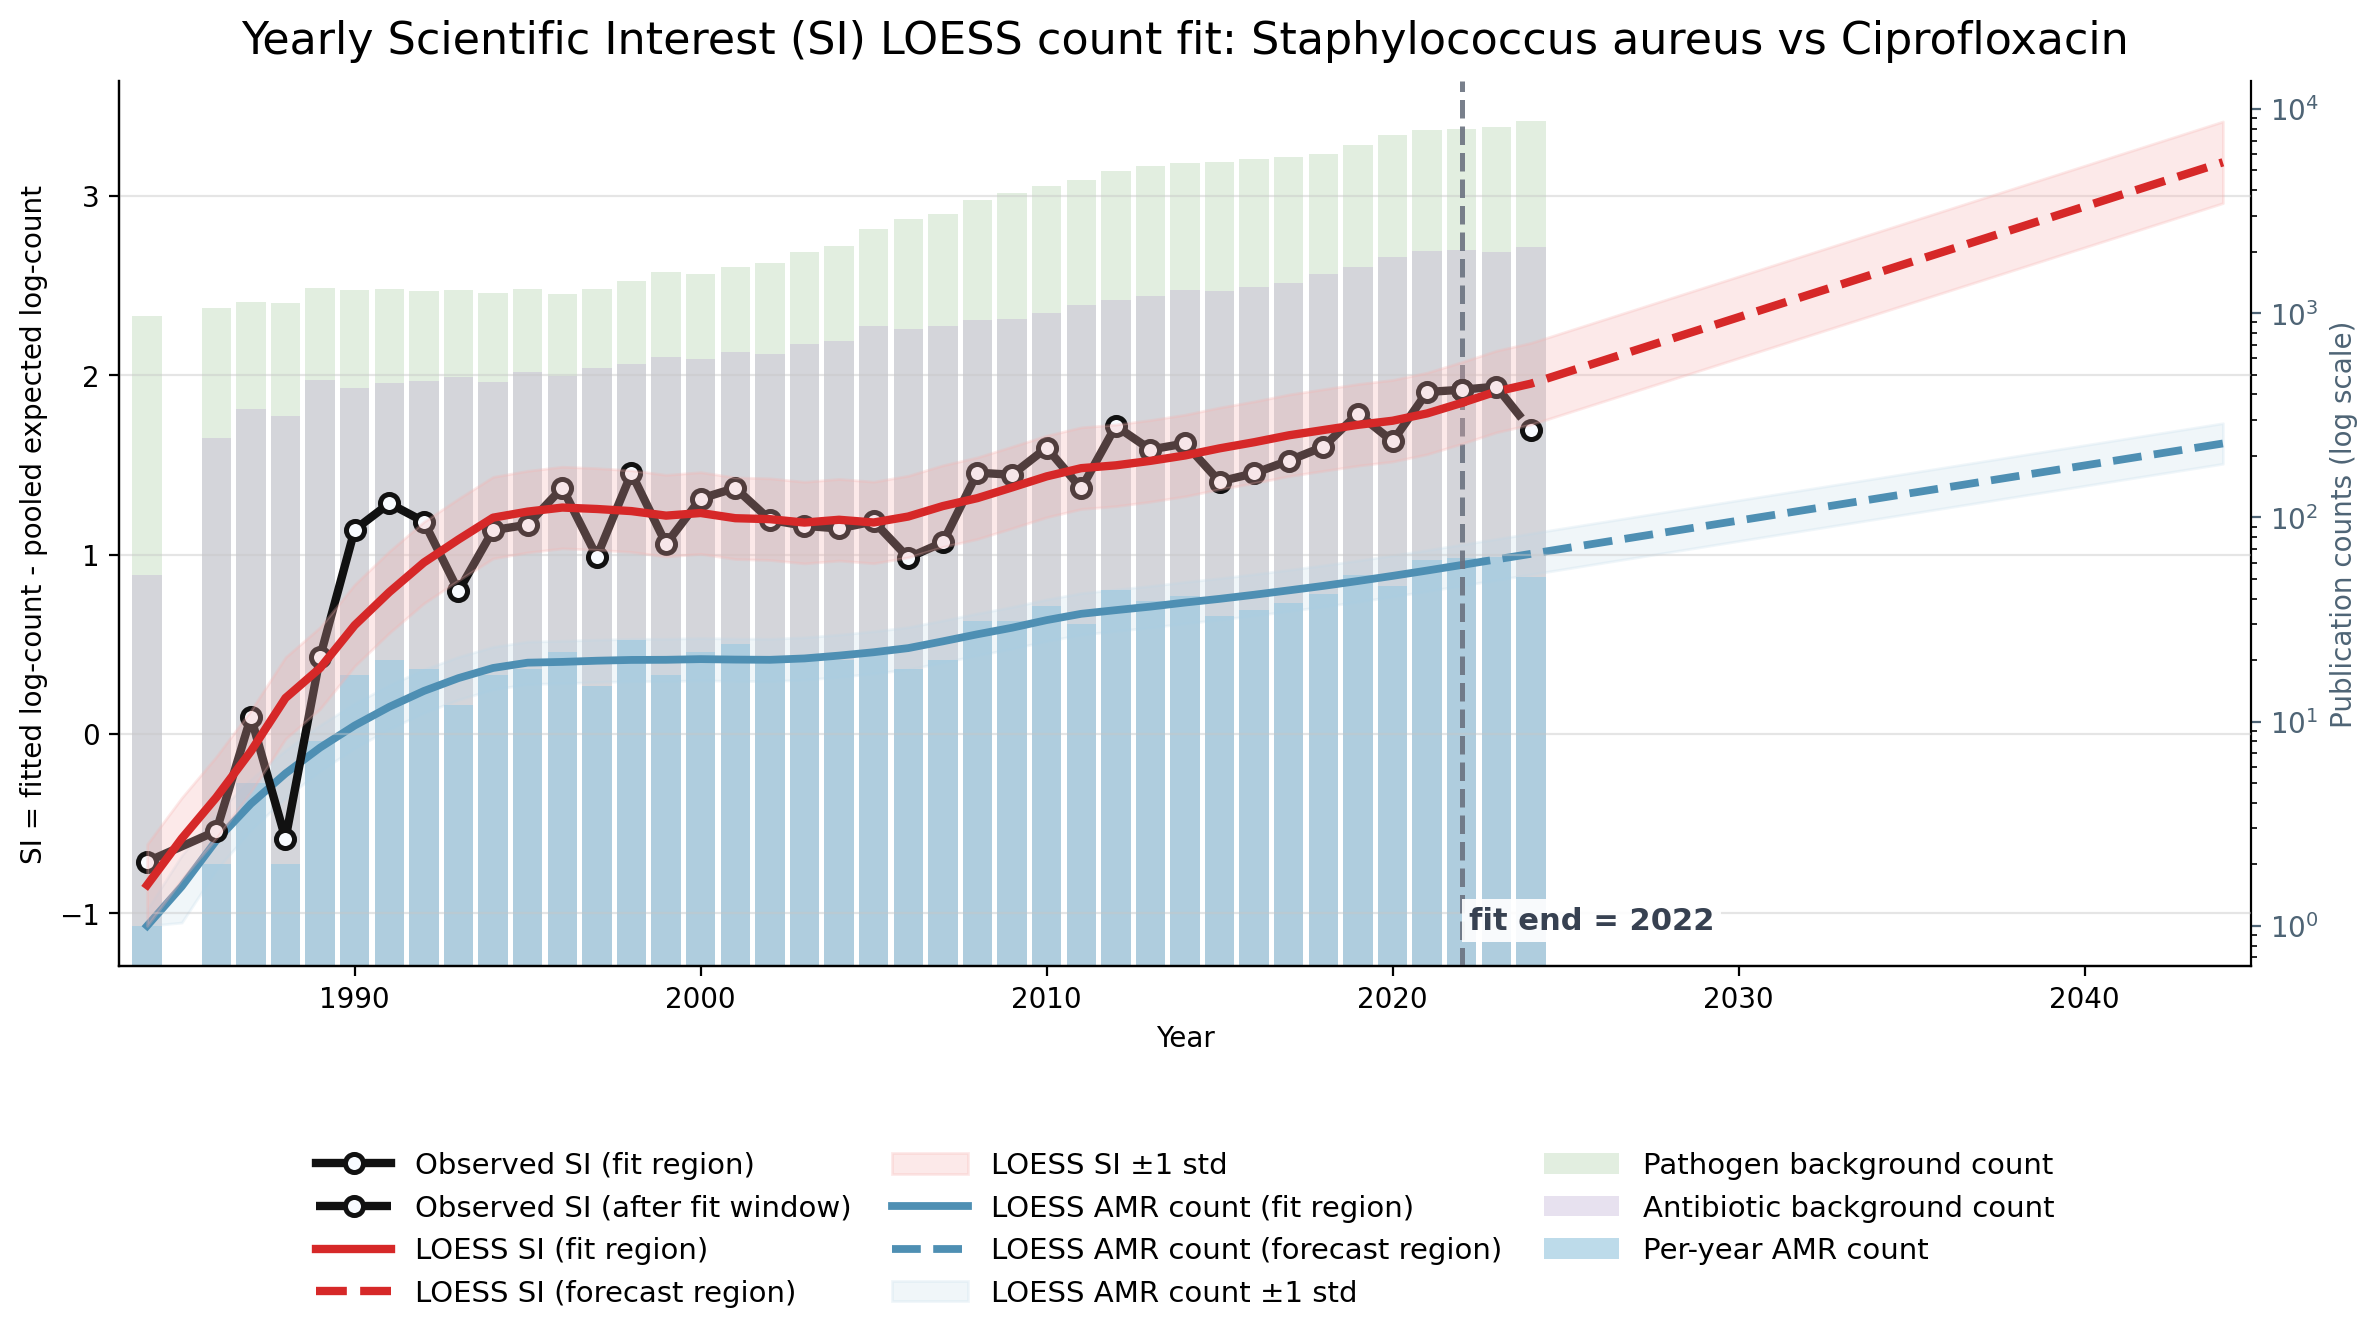

Plotting Klebsiella pneumoniae vs Meropenem


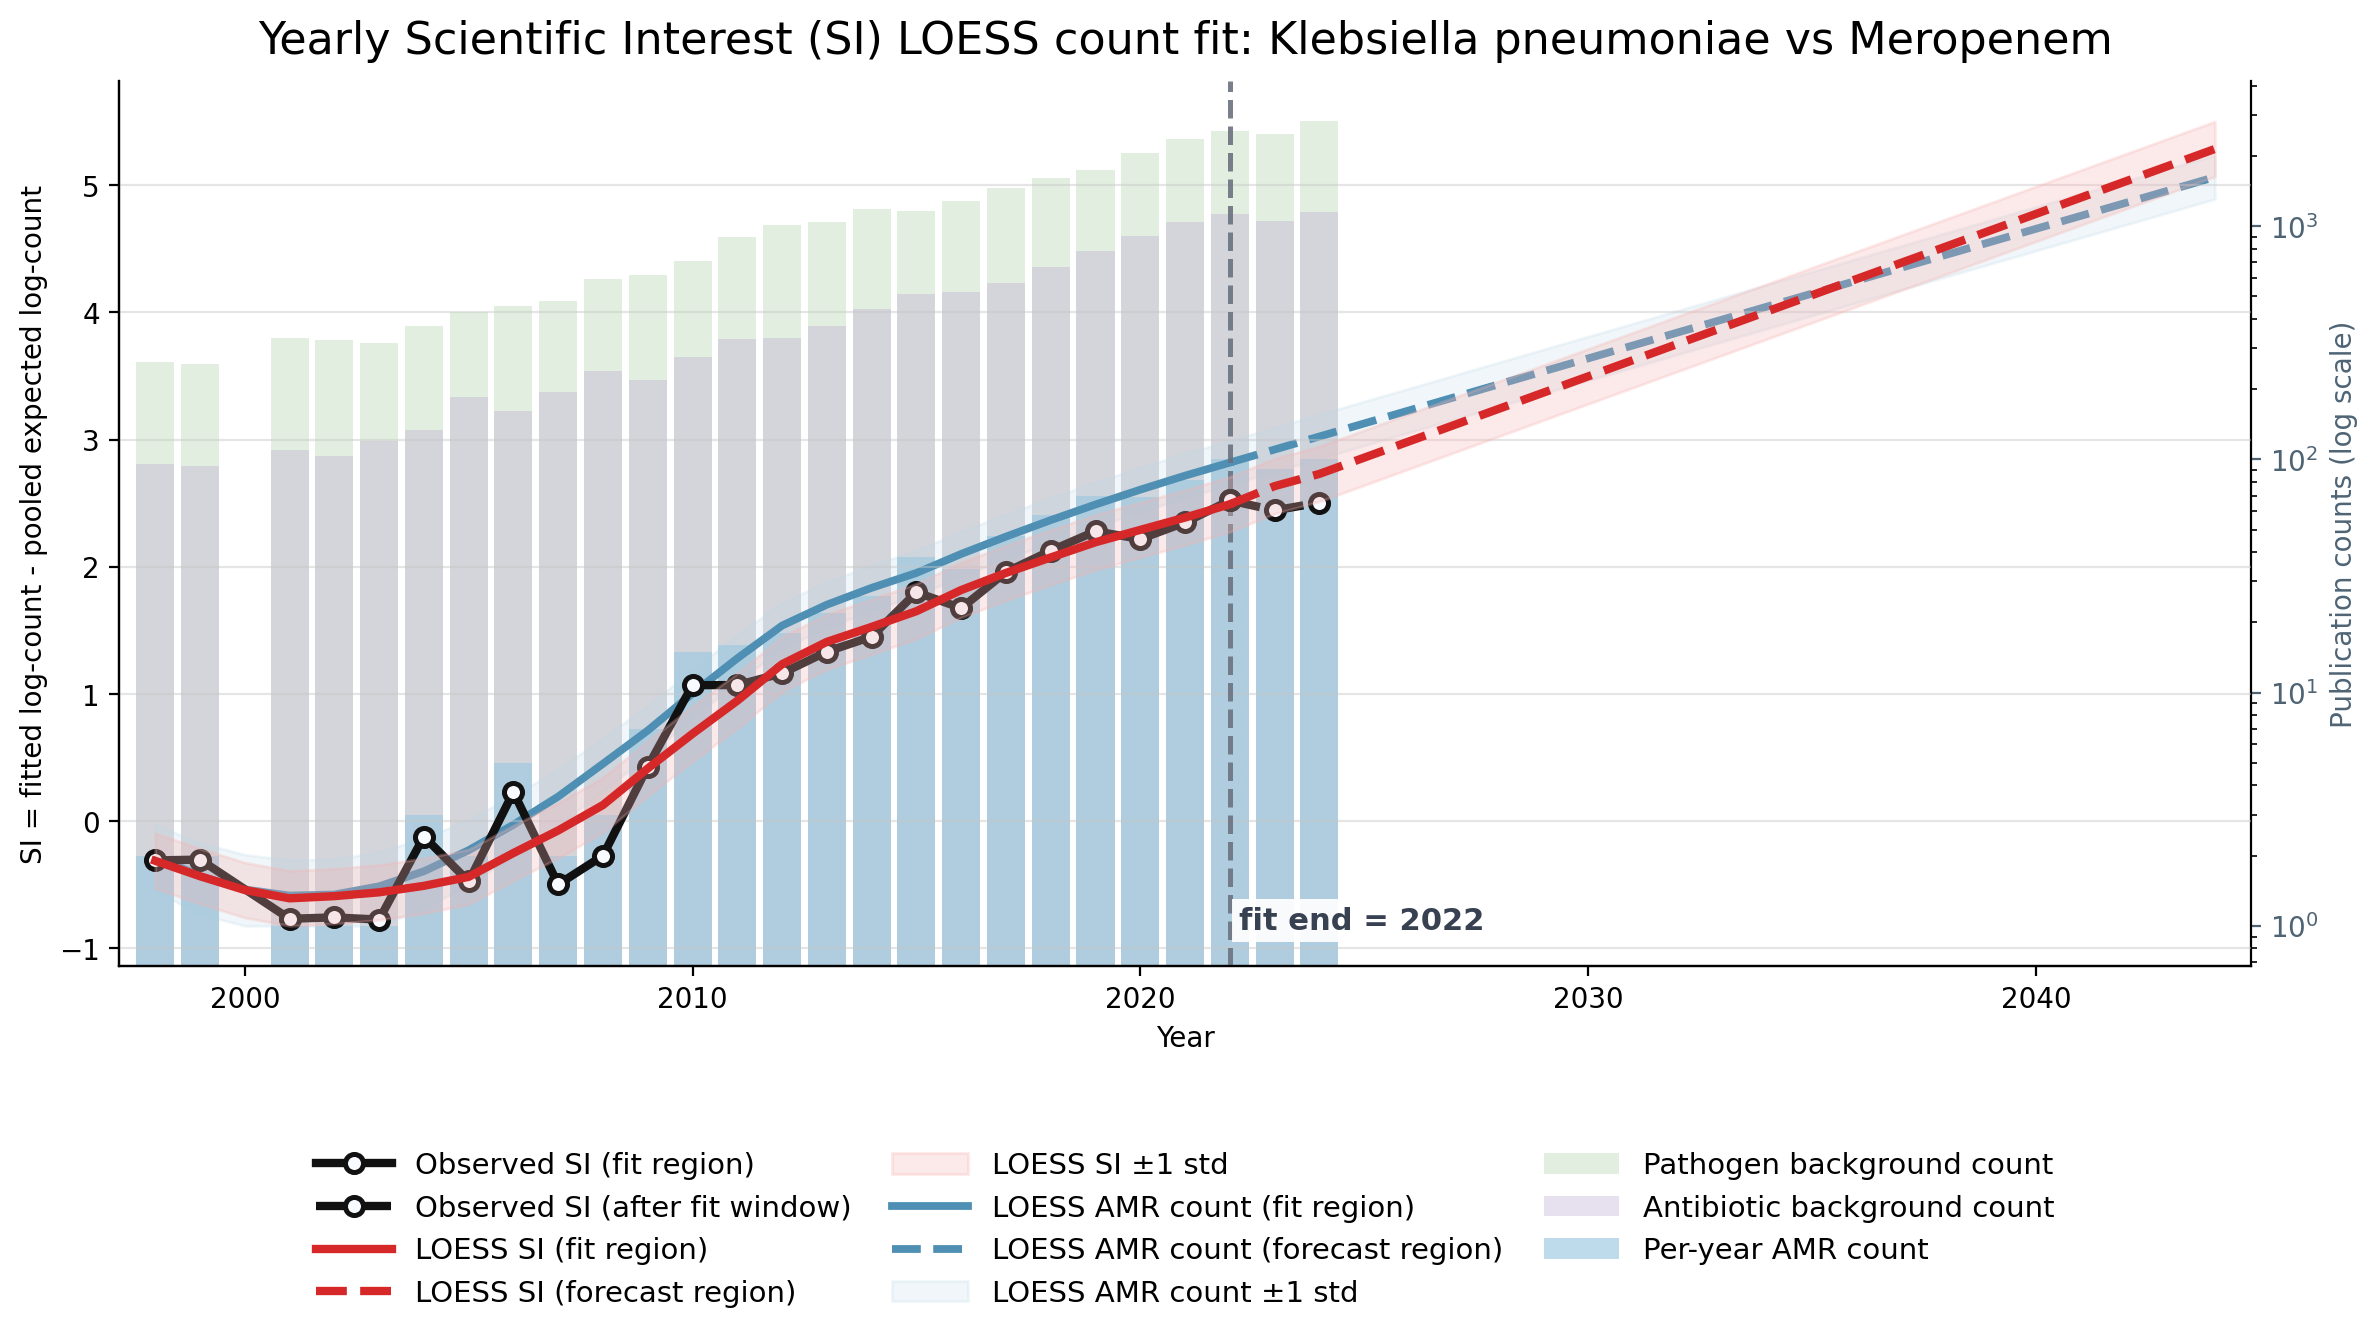

Saved 20 plot PNGs to pareto_pngs_yearly


In [11]:
# Example:
n_pareto_shells = 6
pareto_df = display_si_amr_pareto_front(si_df, n_pareto_shells=n_pareto_shells)
pareto_plot_results = plot_yearly_si_prediction_for_pareto_pairs(
    si_df,
    pareto_df,
    fit_start_year=1970,
    fit_end_year=2022,
    num_additional_years=20,
    loess_frac=0.6,
    loess_degree=2,
    tail_damping_years=None,
    n_pareto_shells=n_pareto_shells,
    save_dir="pareto_pngs_yearly",
)
